# ConvNeXt + Attention-MIL Pallor Classification — Anemia Detection Pipeline

This notebook extends the patch-level ConvNeXt pipeline into a **true Multiple Instance Learning
(MIL) model**: each of the 500 images is treated as a **bag** of its 12 patches, a **ConvNeXt-Tiny**
encodes every patch into a feature vector, and a **gated attention pooling layer** (Ilse, Tomczak &
Welling, 2018) learns *which patches matter most* before combining the resulting bag embedding with
CBC/morphology tabular features for a single **patient-level** pallor classification.

This is the difference from the earlier patch-level notebook: instead of classifying every patch
independently and aggregating predictions afterward by majority vote, the attention mechanism itself
learns to weight and combine patch evidence **during training**, and gives you an interpretable
**attention weight per patch** — i.e. exactly which of the 12 sub-images the model relied on most to
make its call.

### Expected input
Same `anemia_500.zip` structure as before:

```
anemia_500/
├── Original_Images/      # raw patches, e.g. 0001_01_a.png ... 0001_12_a.png
├── RGB_Segmented/        # RGB-segmented versions of the same patches
├── Binary_Segmented/     # binary (cell-mask) versions of the same patches
├── cbc.csv               # record_id, WBC, RBC, HGB, HCT, MCV, MCH, MCHC, RDW_CV, PLT, MPV, differential counts
└── morphology.csv        # record_id, specimen, rbc_morphology, wbc_morphology, platelets, note
```

### Class definition (central pallor as % of cell width)
| Class | Central pallor |
|---|---|
| **Normochromic** | ≤ 33% (1/3) of cell width |
| **Mild Hypochromic** | 33–50% of cell width |
| **Severely Hypochromic** | > 50% of cell width |

### MIL bag label
Each image's ground-truth label is the **median-severity label across its 12 patches** (see Section 7
for the reasoning): a single outlier patch no longer forces the whole bag to Severe, so genuinely mild
cases can actually enter training instead of being swallowed by a max-severity rule. `max_severity_label`
is still computed and stored for audit/comparison, but it is not the training target.

### What this notebook produces
- The same 300 dpi EDA figures as before (class distributions, pallor-ratio histogram, sample
  mosaics, CBC correlation scatter plots).
- An explicit **NaN-cleaning pass** on the merged CBC/morphology fields before any split or training.
- A **ConvNeXt-Tiny + gated-attention MIL + tabular fusion** model trained directly at the
  **bag (image) level**, for the full 30 epochs (no automatic early stopping), with label smoothing,
  gradient clipping, and macro-F1–based checkpointing to favor recall on the minority class.
- Training/validation **loss, accuracy & macro-F1 curves**, a **confusion matrix** with non-overlapping
  wrapped labels, **ROC/PR curves**, and extra imbalance-aware metrics (balanced accuracy, MCC, Cohen's
  kappa, per-class recall) — all at the image level (no post-hoc aggregation needed).
- Test-time augmentation (flip averaging) applied at inference for a further accuracy/recall boost.
- **Attention-weight visualizations** — per-bag bar charts showing which of the 12 patches the model
  attended to most, plus a **Grad-CAM++ heatmap** on the single highest-attention patch per sample bag,
  with an optional SHAP comparison panel.
- Everything zipped for download at the end.


## 1. Setup

In [ ]:
# Install packages not preinstalled in Colab
!pip -q install timm==1.0.9 grad-cam==1.5.4 opencv-python-headless shap --upgrade


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 72.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 112.6 MB/s eta 0:00:00


In [ ]:
import os, re, glob, json, zipfile, warnings, random, textwrap
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms

import timm
from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve, auc,
                              precision_recall_curve, average_precision_score, accuracy_score,
                              f1_score, balanced_accuracy_score, matthews_corrcoef,
                              cohen_kappa_score, recall_score)
from tqdm.auto import tqdm

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

# 300 dpi everywhere
plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.size"] = 10
sns.set_style("whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


## 2. Configuration

In [ ]:
BASE_CLASSES = ["Normochromic", "Mild_Hypochromic", "Severely_Hypochromic"]
# The final model classes are determined AFTER bag-level labels are created.
# Normochromic is optional for this anemia-only dataset; Mild + Severe are required.
CLASSES = BASE_CLASSES.copy()
LABEL2IDX = {c: i for i, c in enumerate(CLASSES)}
IDX2LABEL = {i: c for c, i in LABEL2IDX.items()}
SEVERITY_ORDER = {"Normochromic": 0, "Mild_Hypochromic": 1, "Severely_Hypochromic": 2}

# Human-readable labels used only for plots/reports -- internal values above stay
# underscored so string-equality checks elsewhere in the notebook keep working.
DISPLAY_NAMES = {
    "Normochromic": "Normochromic",
    "Mild_Hypochromic": "Mild Hypochromic",
    "Severely_Hypochromic": "Severely Hypochromic",
}

def pretty(name):
    return DISPLAY_NAMES.get(name, name)

def wrap_label(name, width=11):
    """Wrap a display label onto multiple short lines so it never overlaps
    its neighbors on a confusion-matrix axis."""
    return "\n".join(textwrap.wrap(pretty(name), width=width))

CBC_FEATURES = ["WBC", "RBC", "HGB", "HCT", "MCV", "MCH", "MCHC", "RDW_CV", "PLT", "MPV",
                "NEUT_PCT", "LYMP_PCT", "MONO_PCT", "EOS_PCT", "BASO_PCT",
                "NEUT_ABS", "LYMP_ABS", "MONO_ABS", "EOS_ABS", "BASO_ABS"]

IMG_SIZE       = 224
PATCHES_PER_BAG = 12

# ---- Training-stability settings ----
# The previous run fully fine-tuned an unfrozen ConvNeXt-Tiny at LR=3e-4 with
# batch size 1 on ~350 training bags -- more than enough to wreck the
# pretrained features within a single epoch, which is exactly what the old
# training log showed (val macro-F1 flatlined after epoch 1). Fix: freeze
# most of the backbone, use a much smaller backbone LR than head LR, and
# warm up before the cosine decay.
EPOCHS          = 30      # single source of truth -- do not redefine this later in the notebook
WARMUP_EPOCHS   = 3
HEAD_LR         = 3e-4    # attention pool + tabular MLP + classifier head
BACKBONE_LR     = 5e-6    # lowered from 1e-5: the unfrozen last ConvNeXt stage was still drifting
                           # fast enough (28M-param backbone, ~350 bags) to widen the train/val gap
FREEZE_BACKBONE_UP_TO = 3 # freeze backbone.stem and backbone.stages[0..FREEZE_BACKBONE_UP_TO-1];
                           # backbone.stages[FREEZE_BACKBONE_UP_TO:] stays trainable at BACKBONE_LR
ACCUM_STEPS     = 4        # effective batch size = 4 bags per optimizer step
GRAD_CLIP_NORM  = 1.0
WEIGHT_DECAY    = 3e-4    # raised from 1e-4 -- more L2 pressure given how few bags there are
LABEL_SMOOTHING = 0.10    # raised from 0.05 -- softens overconfident logits on a tiny dataset

# ---- Early stopping (reinstated) ----
# A previous revision of this notebook removed early stopping so every run
# used the full EPOCHS. That is exactly what let training continue for
# 15-20 epochs past the point where val_loss stopped improving: train_loss
# kept falling to ~0.4 while val_loss oscillated between 1.0-1.7 the whole
# time (classic overfitting on ~350 bags with a 28M-param backbone).
# Stopping once val_loss stalls keeps the reported curves representative of
# genuine learning instead of a long, noisy overfitting tail.
EARLY_STOP_PATIENCE = 7    # epochs with no val_loss improvement before stopping
N_FOLDS = 5                # stratified k-fold CV, see Section 13.5 below

CONTENT_ROOT = "/content/data"
RESULTS_ROOT = "/content/results_mil"
FIG_DIR      = f"{RESULTS_ROOT}/figures"
MODEL_DIR    = f"{RESULTS_ROOT}/models"
TABLES_DIR   = f"{RESULTS_ROOT}/tables"
for d in [RESULTS_ROOT, FIG_DIR, MODEL_DIR, TABLES_DIR]:
    os.makedirs(d, exist_ok=True)

def savefig(name):
    path = os.path.join(FIG_DIR, name)
    plt.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)


## 3. Get `anemia_500.zip` into Colab

Large-file-friendly options — pick whichever is easiest, only one is needed.

| Method | Best when |
|---|---|
| **A — Google Drive mount** (recommended) | Zip already uploaded to Drive. Fastest, no browser re-upload. |
| **B — Google Drive share link + `gdown`** | Paste a Drive share link, downloads straight into the VM. |
| **C — Direct URL** | Hosted with a direct download link (Dropbox, S3, etc.). |
| **D — Browser upload** | Last resort — slow/unreliable for large files over weak connections. |


In [ ]:
UPLOAD_METHOD = "drive_share_link"  #@param ["drive_mount", "drive_share_link", "direct_url", "browser_upload"]

DRIVE_ZIP_PATH   = "https://drive.google.com/file/d/1wzpJs8wY9b59f4KGUPIGOiAnfcqLo4j4/view?usp=drive_link"  #@param {type:"string"}  (Method A)
DRIVE_SHARE_LINK = "https://drive.google.com/file/d/1wzpJs8wY9b59f4KGUPIGOiAnfcqLo4j4/view?usp=drive_link"  #@param {type:"string"}  (Method B) e.g. https://drive.google.com/file/d/XXXXXXXX/view?usp=sharing
DIRECT_URL       = ""  #@param {type:"string"}  (Method C) direct https link to the zip

os.makedirs(CONTENT_ROOT, exist_ok=True)
ZIP_PATH = "/content/anemia_500.zip"

if UPLOAD_METHOD == "drive_mount":
    from google.colab import drive
    drive.mount("/content/drive")
    ZIP_PATH = DRIVE_ZIP_PATH
    assert os.path.exists(ZIP_PATH), f"Couldn't find {ZIP_PATH} — check the path in My Drive."

elif UPLOAD_METHOD == "drive_share_link":
    !pip -q install gdown
    import gdown
    assert DRIVE_SHARE_LINK, "Paste a Google Drive share link into DRIVE_SHARE_LINK above."
    m = re.search(r"/d/([a-zA-Z0-9_-]+)", DRIVE_SHARE_LINK) or re.search(r"id=([a-zA-Z0-9_-]+)", DRIVE_SHARE_LINK)
    file_id = m.group(1) if m else DRIVE_SHARE_LINK.strip()
    gdown.download(id=file_id, output=ZIP_PATH, quiet=False)

elif UPLOAD_METHOD == "direct_url":
    assert DIRECT_URL, "Paste a direct download URL into DIRECT_URL above."
    !wget -q --show-progress -O "{ZIP_PATH}" "{DIRECT_URL}"

elif UPLOAD_METHOD == "browser_upload":
    from google.colab import files
    print("Select anemia_500.zip to upload (this can take a while for large files — don't close the tab)...")
    uploaded = files.upload()
    ZIP_PATH = list(uploaded.keys())[0]

else:
    raise ValueError(f"Unknown UPLOAD_METHOD: {UPLOAD_METHOD}")

print(f"Using zip: {ZIP_PATH}  ({os.path.getsize(ZIP_PATH) / 1e6:.1f} MB)")


Downloading...
From (original): https://drive.google.com/uc?id=1wzpJs8wY9b59f4KGUPIGOiAnfcqLo4j4
From (redirected): https://drive.google.com/uc?id=1wzpJs8wY9b59f4KGUPIGOiAnfcqLo4j4&confirm=t&uuid=29e12b89-701d-4c4c-a379-38c1062447a0
To: /content/anemia_500.zip
100%|██████████| 1.98G/1.98G [00:25<00:00, 76.9MB/s]

Using zip: /content/anemia_500.zip  (1976.2 MB)


In [ ]:
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(CONTENT_ROOT)

ROOT = os.path.join(CONTENT_ROOT, "anemia_500")
ORIG_DIR  = os.path.join(ROOT, "Original_Images")
RGB_DIR   = os.path.join(ROOT, "RGB_Segmented")
BIN_DIR   = os.path.join(ROOT, "Binary_Segmented")
CBC_CSV   = os.path.join(ROOT, "cbc.csv")
MORPH_CSV = os.path.join(ROOT, "morphology.csv")

for name, d in [("Original_Images", ORIG_DIR), ("RGB_Segmented", RGB_DIR), ("Binary_Segmented", BIN_DIR)]:
    n = len(glob.glob(os.path.join(d, "*")))
    print(f"{name}: {n} files")

print("cbc.csv exists:", os.path.exists(CBC_CSV))
print("morphology.csv exists:", os.path.exists(MORPH_CSV))


Original_Images: 6000 files
RGB_Segmented: 6000 files
Binary_Segmented: 6000 files
cbc.csv exists: True
morphology.csv exists: True


## 4. Parse patch filenames
`IIII_PP_a.<ext>`, e.g. `0001_01_a.png` → `record_id=1`, `patch_id=1`.

In [ ]:
PATCH_RE = re.compile(r"^(\d+)_(\d+)_[A-Za-z]\.\w+$")

def parse_patch_filename(path):
    base = os.path.basename(path)
    m = PATCH_RE.match(base)
    if not m:
        return None, None
    return int(m.group(1)), int(m.group(2))

sample_files = sorted(glob.glob(os.path.join(ORIG_DIR, "*")))[:5]
for f in sample_files:
    print(os.path.basename(f), "->", parse_patch_filename(f))


0001_01_a.png -> (1, 1)
0001_02_a.png -> (1, 2)
0001_03_a.png -> (1, 3)
0001_04_a.png -> (1, 4)
0001_05_a.png -> (1, 5)


## 5. Measure central pallor ratio per patch — corrected

**Important correction:** the original notebook labeled 5,997/6,000 patches as Severe because its
75th-percentile threshold included bright boundary/background pixels and then measured their entire
horizontal span. The corrected method below uses the RBC component, Lab lightness/chroma, distance
from the cell boundary, and a contiguous central run.

The class thresholds remain:

- **Normochromic:** ≤33%
- **Mild Hypochromic:** >33% to ≤50%
- **Severely Hypochromic:** >50%

The model is **not allowed to invent a Mild class**. Mild training bags must come from actual image
measurements or expert annotations.


In [ ]:
def _largest_valid_component(mask):
    """Return a clean foreground mask. Handles white-cell-on-black and black-cell-on-white masks."""
    mask = (mask > 0).astype(np.uint8)
    h, w = mask.shape
    candidates = []
    for m in [mask, 1 - mask]:
        n, labels, stats, cents = cv2.connectedComponentsWithStats(m, 8)
        for k in range(1, n):
            x, y, ww, hh, area = stats[k]
            if area < max(50, 0.01 * h * w):
                continue
            # Prefer a large component that is not simply the whole image/background.
            border = (x == 0 or y == 0 or x + ww >= w or y + hh >= h)
            score = area * (0.35 if border else 1.0)
            candidates.append((score, area, labels == k))
    if not candidates:
        return mask.astype(np.uint8)
    candidates.sort(key=lambda z: z[0], reverse=True)
    return candidates[0][2].astype(np.uint8)


def compute_pallor_ratio(bin_path, rgb_path, debug=False):
    """
    Robust central-pallor estimate.

    The previous implementation thresholded the brightest 25% of ALL pixels inside
    the mask and then measured the complete horizontal span of those pixels. That
    can label almost every RBC as 100% pallor because bright boundary/background
    pixels are included. Here we:
      1) clean the binary mask and select the RBC component,
      2) use Lab lightness + chroma to identify pale pixels,
      3) restrict pallor to the CENTRAL region using the distance transform,
      4) measure the contiguous central run through the centroid row.
    """
    binm = cv2.imread(bin_path, cv2.IMREAD_GRAYSCALE)
    bgr  = cv2.imread(rgb_path, cv2.IMREAD_COLOR)
    if binm is None or bgr is None:
        return None

    cell_mask = _largest_valid_component(binm)

    # Clean small holes/noise.
    cell_mask = cv2.morphologyEx(cell_mask, cv2.MORPH_CLOSE, np.ones((5,5), np.uint8))
    cell_mask = cv2.morphologyEx(cell_mask, cv2.MORPH_OPEN, np.ones((3,3), np.uint8))

    ys, xs = np.where(cell_mask > 0)
    if len(xs) < 100:
        return None

    # Centroid and central horizontal width.
    M = cv2.moments(cell_mask, binaryImage=True)
    if M["m00"] == 0:
        return None
    cx = int(round(M["m10"] / M["m00"]))
    cy = int(round(M["m01"] / M["m00"]))

    # Use the median x extent in a narrow centroid band for a stable cell width.
    band = max(2, int(round(0.02 * min(cell_mask.shape))))
    band_y = np.arange(max(0, cy-band), min(cell_mask.shape[0], cy+band+1))
    row_widths = []
    for yy in band_y:
        xx = np.where(cell_mask[yy] > 0)[0]
        if len(xx) > 5:
            row_widths.append((xx.min(), xx.max()))
    if not row_widths:
        return None
    left = int(np.median([a for a,b in row_widths]))
    right = int(np.median([b for a,b in row_widths]))
    cell_width = right - left + 1
    if cell_width <= 10:
        return None

    # Lab: pallor is relatively high L* and low chroma.
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    L = lab[...,0] / 255.0
    a = lab[...,1] - 128.0
    bb = lab[...,2] - 128.0
    chroma = np.sqrt(a*a + bb*bb)
    inside = cell_mask > 0

    # Normalize lightness/chroma within this RBC.
    lvals = L[inside]
    cvals = chroma[inside]
    l_hi = np.percentile(lvals, 70)
    c_lo = np.percentile(cvals, 45)

    pale = (L >= l_hi) & (chroma <= c_lo) & inside

    # Force pallor to be central: distance from the RBC boundary must be substantial.
    dist = cv2.distanceTransform(cell_mask.astype(np.uint8), cv2.DIST_L2, 5)
    maxdist = float(dist.max())
    if maxdist <= 1:
        return None
    central = dist >= (0.22 * maxdist)
    pallor = (pale & central).astype(np.uint8)

    # Light morphological cleanup.
    pallor = cv2.morphologyEx(pallor, cv2.MORPH_OPEN, np.ones((3,3), np.uint8))
    pallor = cv2.morphologyEx(pallor, cv2.MORPH_CLOSE, np.ones((5,5), np.uint8))

    # Recompute centroid-row interval and find the contiguous pale run around cx.
    yy0 = int(np.clip(cy, 0, pallor.shape[0]-1))
    row = pallor[yy0]
    valid_x = np.where(cell_mask[yy0] > 0)[0]
    if len(valid_x) < 5:
        # fallback to nearest row with a valid cell
        for delta in range(1, 8):
            for yy in [cy-delta, cy+delta]:
                if 0 <= yy < pallor.shape[0]:
                    valid_x = np.where(cell_mask[yy] > 0)[0]
                    if len(valid_x) >= 5:
                        yy0 = yy
                        row = pallor[yy]
                        break
            if len(valid_x) >= 5:
                break
    if len(valid_x) < 5:
        return None

    left, right = valid_x.min(), valid_x.max()
    cx = int(np.clip(cx, left, right))

    # Find the contiguous pallor interval containing the cell centre.
    pidx = np.where(row[left:right+1] > 0)[0] + left
    if len(pidx) == 0:
        pallor_width = 0
    else:
        # Connected runs; choose the run nearest the centroid.
        runs = []
        s = pidx[0]; prev = pidx[0]
        for x in pidx[1:]:
            if x == prev + 1:
                prev = x
            else:
                runs.append((s, prev))
                s = prev = x
        runs.append((s, prev))
        containing = [r for r in runs if r[0] <= cx <= r[1]]
        if containing:
            run = containing[0]
        else:
            run = min(runs, key=lambda r: abs(((r[0]+r[1])/2) - cx))
        pallor_width = run[1] - run[0] + 1

    ratio = 100.0 * pallor_width / cell_width

    # A second, area-based centrality estimate stabilizes one-pixel centerline noise.
    central_cell = (dist >= 0.15 * maxdist) & inside
    central_area = int(np.sum(pallor & central_cell))
    central_area_total = int(np.sum(central_cell))
    if central_area_total > 0:
        area_fraction = 100.0 * central_area / central_area_total
        # Blend width and area estimates rather than letting one noisy row dominate.
        ratio = 0.70 * ratio + 0.30 * min(100.0, area_fraction)

    return float(np.clip(ratio, 0, 100))


def label_from_ratio(ratio):
    if ratio is None or not np.isfinite(ratio):
        return None
    if ratio <= 33:
        return "Normochromic"
    elif ratio <= 50:
        return "Mild_Hypochromic"
    else:
        return "Severely_Hypochromic"


In [ ]:
rows = []
orig_files = sorted(glob.glob(os.path.join(ORIG_DIR, "*")))

for f in tqdm(orig_files, desc="Measuring robust central pallor"):
    base = os.path.basename(f)
    rid, pid = parse_patch_filename(f)
    if rid is None:
        continue

    rgb_path = os.path.join(RGB_DIR, base)
    bin_path = os.path.join(BIN_DIR, base)
    if not (os.path.exists(rgb_path) and os.path.exists(bin_path)):
        continue

    ratio = compute_pallor_ratio(bin_path, rgb_path)
    label = label_from_ratio(ratio)
    if label is None:
        continue

    rows.append({
        "record_id": rid, "patch_id": pid, "filename": base,
        "orig_path": f, "rgb_path": rgb_path, "bin_path": bin_path,
        "pallor_ratio": ratio, "label": label,
    })

patch_df = pd.DataFrame(rows)
patch_df.to_csv(f"{TABLES_DIR}/patch_pallor_labels.csv", index=False)

print("Total labeled patches:", len(patch_df))
print("\nPATCH-LEVEL CLASS COUNTS:")
print(patch_df["label"].value_counts().reindex(BASE_CLASSES, fill_value=0))

print("\nPALLOR-RATIO SUMMARY:")
print(patch_df["pallor_ratio"].describe(percentiles=[.01,.05,.25,.50,.75,.95,.99]))

# Important diagnostic: the old method produced 5,997/6,000 severe patches.
# Stop early only if the new method still collapses to one class.
if len(patch_df):
    print("\nRatio range:", round(patch_df.pallor_ratio.min(),2), "to", round(patch_df.pallor_ratio.max(),2))
    print("Unique ratio values:", patch_df.pallor_ratio.nunique())

patch_df.head()


Measuring robust central pallor:   0%|          | 0/6000 [00:00<?, ?it/s]

Total labeled patches: 6000

PATCH-LEVEL CLASS COUNTS:
label
Normochromic            4141
Mild_Hypochromic        1286
Severely_Hypochromic     573
Name: count, dtype: int64

PALLOR-RATIO SUMMARY:
count    6000.000000
mean       30.804996
std        13.326326
min         0.034007
1%         14.421356
5%         17.565564
25%        21.825342
50%        26.933721
75%        35.619281
95%        58.704519
99%        80.175528
max        96.807292
Name: pallor_ratio, dtype: float64

Ratio range: 0.03 to 96.81
Unique ratio values: 5969


,record_id,patch_id,filename,orig_path,rgb_path,bin_path,pallor_ratio,label
0,1,1,0001_01_a.png,/content/data/anemia_500/Original_Images/0001_...,/content/data/anemia_500/RGB_Segmented/0001_01...,/content/data/anemia_500/Binary_Segmented/0001...,23.312194,Normochromic
1,1,2,0001_02_a.png,/content/data/anemia_500/Original_Images/0001_...,/content/data/anemia_500/RGB_Segmented/0001_02...,/content/data/anemia_500/Binary_Segmented/0001...,20.962214,Normochromic
2,1,3,0001_03_a.png,/content/data/anemia_500/Original_Images/0001_...,/content/data/anemia_500/RGB_Segmented/0001_03...,/content/data/anemia_500/Binary_Segmented/0001...,25.176675,Normochromic
3,1,4,0001_04_a.png,/content/data/anemia_500/Original_Images/0001_...,/content/data/anemia_500/RGB_Segmented/0001_04...,/content/data/anemia_500/Binary_Segmented/0001...,20.071170,Normochromic
4,1,5,0001_05_a.png,/content/data/anemia_500/Original_Images/0001_...,/content/data/anemia_500/RGB_Segmented/0001_05...,/content/data/anemia_500/Binary_Segmented/0001...,20.333946,Normochromic


## 6. Merge with `cbc.csv` and `morphology.csv`

In [ ]:
cbc_df = pd.read_csv(CBC_CSV)
morph_df = pd.read_csv(MORPH_CSV)

# Prevent duplicate patient rows from multiplying MIL bags during the merge.
cbc_df = cbc_df.drop_duplicates(subset=["record_id"], keep="first").copy()
morph_df = morph_df.drop_duplicates(subset=["record_id"], keep="first").copy()

cbc_df["record_id"] = cbc_df["record_id"].astype(int)
morph_df["record_id"] = morph_df["record_id"].astype(int)

CBC_FEATURES = [c for c in CBC_FEATURES if c in cbc_df.columns]
print("Using CBC features:", CBC_FEATURES)

full_df = patch_df.merge(cbc_df, on="record_id", how="left")
full_df = full_df.merge(morph_df[["record_id", "rbc_morphology"]], on="record_id", how="left")

# ---- NaN report + cleanup on the merged patch-level table ----
na_counts = full_df.isna().sum()
na_counts = na_counts[na_counts > 0]
if len(na_counts):
    print("\nColumns with missing values after the CBC/morphology merge:")
    print(na_counts)
else:
    print("\nNo missing values after the CBC/morphology merge.")

# Columns that are entirely missing carry no information — drop them outright.
all_nan_cols = [c for c in full_df.columns if full_df[c].isna().all()]
if all_nan_cols:
    print("Dropping fully-NaN columns:", all_nan_cols)
    full_df = full_df.drop(columns=all_nan_cols)
    CBC_FEATURES = [c for c in CBC_FEATURES if c not in all_nan_cols]

full_df.to_csv(f"{TABLES_DIR}/patch_level_full.csv", index=False)
full_df.head()


Using CBC features: ['WBC', 'RBC', 'HGB', 'HCT', 'MCV', 'MCH', 'MCHC', 'RDW_CV', 'PLT', 'MPV', 'NEUT_PCT', 'LYMP_PCT', 'MONO_PCT', 'EOS_PCT', 'BASO_PCT', 'NEUT_ABS', 'LYMP_ABS', 'MONO_ABS', 'EOS_ABS', 'BASO_ABS']

Columns with missing values after the CBC/morphology merge:
WBC                 24
RBC                 36
HGB                 24
HCT                 72
MCV                 24
MCH                 48
MCHC                84
RDW_CV            2448
PLT                 48
MPV               2172
NEUT_PCT          2736
LYMP_PCT          2760
MONO_PCT          2784
EOS_PCT           2808
BASO_PCT          2832
NEUT_ABS          3024
LYMP_ABS          2976
MONO_ABS          3180
EOS_ABS           3084
BASO_ABS          3120
rbc_morphology      48
dtype: int64


,record_id,patch_id,filename,orig_path,rgb_path,bin_path,pallor_ratio,label,WBC,RBC,...,LYMP_PCT,MONO_PCT,EOS_PCT,BASO_PCT,NEUT_ABS,LYMP_ABS,MONO_ABS,EOS_ABS,BASO_ABS,rbc_morphology
0,1,1,0001_01_a.png,/content/data/anemia_500/Original_Images/0001_...,/content/data/anemia_500/RGB_Segmented/0001_01...,/content/data/anemia_500/Binary_Segmented/0001...,23.312194,Normochromic,8.49,4.37,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Peripheral smear shows microcytic hypochromic ...
1,1,2,0001_02_a.png,/content/data/anemia_500/Original_Images/0001_...,/content/data/anemia_500/RGB_Segmented/0001_02...,/content/data/anemia_500/Binary_Segmented/0001...,20.962214,Normochromic,8.49,4.37,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Peripheral smear shows microcytic hypochromic ...
2,1,3,0001_03_a.png,/content/data/anemia_500/Original_Images/0001_...,/content/data/anemia_500/RGB_Segmented/0001_03...,/content/data/anemia_500/Binary_Segmented/0001...,25.176675,Normochromic,8.49,4.37,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Peripheral smear shows microcytic hypochromic ...
3,1,4,0001_04_a.png,/content/data/anemia_500/Original_Images/0001_...,/content/data/anemia_500/RGB_Segmented/0001_04...,/content/data/anemia_500/Binary_Segmented/0001...,20.071170,Normochromic,8.49,4.37,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Peripheral smear shows microcytic hypochromic ...
4,1,5,0001_05_a.png,/content/data/anemia_500/Original_Images/0001_...,/content/data/anemia_500/RGB_Segmented/0001_05...,/content/data/anemia_500/Binary_Segmented/0001...,20.333946,Normochromic,8.49,4.37,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Peripheral smear shows microcytic hypochromic ...


## 7. Build MIL bags — corrected bag-level labeling

The original notebook used **maximum severity across 12 patches**. That is inappropriate here because
one severe-looking patch makes the entire image Severe, even if the other 11 patches are mild.

For this version, the bag label is derived from the **median pallor ratio across the 12 patches**.
This represents the dominant RBC phenotype more robustly and allows genuine Mild bags to enter training.

`max_severity_label` is retained for audit/comparison but is **not** used as the training target.


In [ ]:
def aggregate_bag(group):
    mean_ratio = float(group["pallor_ratio"].mean())
    median_ratio = float(group["pallor_ratio"].median())
    majority = group["label"].value_counts().idxmax()
    max_sev = max(group["label"], key=lambda l: SEVERITY_ORDER[l])

    # IMPORTANT FIX:
    # Do NOT use max severity as the training label. A single severe-looking
    # patch was forcing every bag to Severe, even when the field was mostly mild.
    # The image-level label now represents the dominant/median pallor phenotype.
    bag_label = label_from_ratio(median_ratio)

    return pd.Series({
        "majority_label": majority,
        "max_severity_label": max_sev,
        "bag_label": bag_label,
        "mean_pallor_ratio": mean_ratio,
        "median_pallor_ratio": median_ratio,
        "n_patches": len(group),
    })

bag_labels = patch_df.groupby("record_id", group_keys=False).apply(aggregate_bag).reset_index()
bag_df = bag_labels.merge(cbc_df, on="record_id", how="left")
bag_df = bag_df.merge(morph_df[["record_id", "rbc_morphology"]], on="record_id", how="left")
bag_df = bag_df.drop_duplicates(subset=["record_id"], keep="first").reset_index(drop=True)

print("Total bags (images):", len(bag_df))
print("\nBAG-LEVEL CLASS COUNTS:")
print(bag_df["bag_label"].value_counts().reindex(BASE_CLASSES, fill_value=0))
print("Patches per bag — min/median/max:",
      bag_df["n_patches"].min(), bag_df["n_patches"].median(), bag_df["n_patches"].max())

# Normochromic is optional in this anemia dataset. Mild and Severe are required.
active = [c for c in BASE_CLASSES if c in set(bag_df["bag_label"].dropna())]
if "Mild_Hypochromic" not in active or "Severely_Hypochromic" not in active:
    raise RuntimeError(
        "MILD CLASS STILL NOT AVAILABLE AT BAG LEVEL. "
        "The model cannot learn a class that is absent from the labels. "
        "Inspect patch_pallor_labels.csv and the saved sample figures. "
        "If Mild_Hypochromic remains absent after this corrected pallor measurement, "
        "you need genuinely mild RBC/image cases or expert pallor annotations; do not fabricate labels."
    )

# Dynamically remove Normochromic when no normochromic bags exist.
CLASSES = active
LABEL2IDX = {c: i for i, c in enumerate(CLASSES)}
IDX2LABEL = {i: c for c, i in LABEL2IDX.items()}
print("\nACTIVE MODEL CLASSES:", CLASSES)

bag_df.head()


Total bags (images): 500

BAG-LEVEL CLASS COUNTS:
bag_label
Normochromic            399
Mild_Hypochromic         87
Severely_Hypochromic     14
Name: count, dtype: int64
Patches per bag — min/median/max: 12 12.0 12

ACTIVE MODEL CLASSES: ['Normochromic', 'Mild_Hypochromic', 'Severely_Hypochromic']


,record_id,majority_label,max_severity_label,bag_label,mean_pallor_ratio,median_pallor_ratio,n_patches,WBC,RBC,HGB,...,LYMP_PCT,MONO_PCT,EOS_PCT,BASO_PCT,NEUT_ABS,LYMP_ABS,MONO_ABS,EOS_ABS,BASO_ABS,rbc_morphology
0,1,Normochromic,Mild_Hypochromic,Normochromic,26.445737,23.121477,12,8.49,4.37,10.1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Peripheral smear shows microcytic hypochromic ...
1,2,Normochromic,Mild_Hypochromic,Normochromic,23.732505,21.464416,12,9.16,4.94,12.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Peripheral smear shows normocytic hypochromic ...
2,3,Normochromic,Mild_Hypochromic,Normochromic,22.916735,19.803973,12,21.29,4.46,10.8,...,77.9,2.4,3.1,0.6,3.39,16.59,0.52,0.66,0.13,Peripheral smear shows microcytic hypochromic ...
3,4,Severely_Hypochromic,Severely_Hypochromic,Severely_Hypochromic,48.674104,50.429131,12,1.95,2.10,5.9,...,50.8,12.3,0.0,0.0,0.72,0.99,0.24,0.00,0.00,Peripheral smear shows microcytic hypochromic ...
4,5,Normochromic,Severely_Hypochromic,Normochromic,30.119749,30.070977,12,11.87,4.85,7.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Peripheral smear shows microcytic hypochromic ...


### 7.1 Eliminate NaN fields at bag level

The left-merge with `cbc.csv` / `morphology.csv` can leave missing values behind whenever a
record has no matching CBC or morphology row. Before this table is split into train/val/test or
fed to the tabular-fusion branch, we:

1. Report every column that has missing values.
2. Drop any column that is **entirely** NaN (uninformative).
3. Fill the categorical `rbc_morphology` field's missing entries with an explicit `"Unknown"`
   category (dropping those bags would waste image data that is otherwise complete).
4. Drop any bag that is missing its own `bag_label` / `median_pallor_ratio` — those rows are
   unusable no matter what.
5. Drop any bag whose CBC row is **entirely** missing — imputing every lab value for a whole
   patient at once would just insert the training-set median across the board, which is
   misleadingly precise. Bags with only a few missing individual CBC values are kept; those are
   handled properly downstream by the median `SimpleImputer` fit only on the training split.


In [ ]:
na_counts = bag_df.isna().sum()
na_counts = na_counts[na_counts > 0]
if len(na_counts):
    print("Missing values in bag_df before cleaning:")
    print(na_counts)
else:
    print("No missing values in bag_df before cleaning.")

# ------------------------------------------------------------
# COLUMN-WISE NaN elimination (rows/bags are never dropped here).
#
# Only columns that are ENTIRELY missing get dropped (no median/mode is
# even possible for those). Every other column -- however much missing
# data it has -- is kept and handled by the SimpleImputer fitted in
# Section 10, which exists specifically to fill gaps like this. Dropping
# columns for partial missingness was removing CBC features unnecessarily;
# imputation is the right tool here, not deletion.
# ------------------------------------------------------------
if "rbc_morphology" in bag_df.columns:
    bag_df["rbc_morphology"] = bag_df["rbc_morphology"].fillna("Unknown")

all_nan_cols = [c for c in bag_df.columns
                if c != "rbc_morphology" and bag_df[c].isna().all()]

critical_cols = [c for c in ["bag_label", "median_pallor_ratio"] if c in bag_df.columns and bag_df[c].isna().any()]
if critical_cols:
    raise RuntimeError(
        f"Unexpected missing values in critical column(s) {critical_cols}. "
        "These are derived directly from aggregate_bag() and should never be "
        "NaN -- investigate that function."
    )

if all_nan_cols:
    print("\nDropping fully-empty columns (no valid values at all):", all_nan_cols)
    bag_df = bag_df.drop(columns=all_nan_cols)
    CBC_FEATURES = [c for c in CBC_FEATURES if c not in all_nan_cols]
else:
    print("\nNo fully-empty columns to drop.")

print("CBC_FEATURES after cleaning:", CBC_FEATURES)

remaining_na = bag_df.isna().sum()
remaining_na = remaining_na[remaining_na > 0]
print("\nRemaining missing values in bag_df (handled by the Section 10 imputer):")
print(remaining_na if len(remaining_na) else "None.")

bag_df.to_csv(f"{TABLES_DIR}/bag_level_labels.csv", index=False)
print(f"\nTotal bags after NaN cleaning: {len(bag_df)} (unchanged -- no rows were dropped)")

Missing values in bag_df before cleaning:
WBC                 2
RBC                 3
HGB                 2
HCT                 6
MCV                 2
MCH                 4
MCHC                7
RDW_CV            204
PLT                 4
MPV               181
NEUT_PCT          228
LYMP_PCT          230
MONO_PCT          232
EOS_PCT           234
BASO_PCT          236
NEUT_ABS          252
LYMP_ABS          248
MONO_ABS          265
EOS_ABS           257
BASO_ABS          260
rbc_morphology      4
dtype: int64

No fully-empty columns to drop.
CBC_FEATURES after cleaning: ['WBC', 'RBC', 'HGB', 'HCT', 'MCV', 'MCH', 'MCHC', 'RDW_CV', 'PLT', 'MPV', 'NEUT_PCT', 'LYMP_PCT', 'MONO_PCT', 'EOS_PCT', 'BASO_PCT', 'NEUT_ABS', 'LYMP_ABS', 'MONO_ABS', 'EOS_ABS', 'BASO_ABS']

Remaining missing values in bag_df (handled by the Section 10 imputer):
WBC           2
RBC           3
HGB           2
HCT           6
MCV           2
MCH           4
MCHC          7
RDW_CV      204
PLT           4
MPV        

## 8. Exploratory figures (300 dpi)

Saved: /content/results_mil/figures/01_class_distribution.png


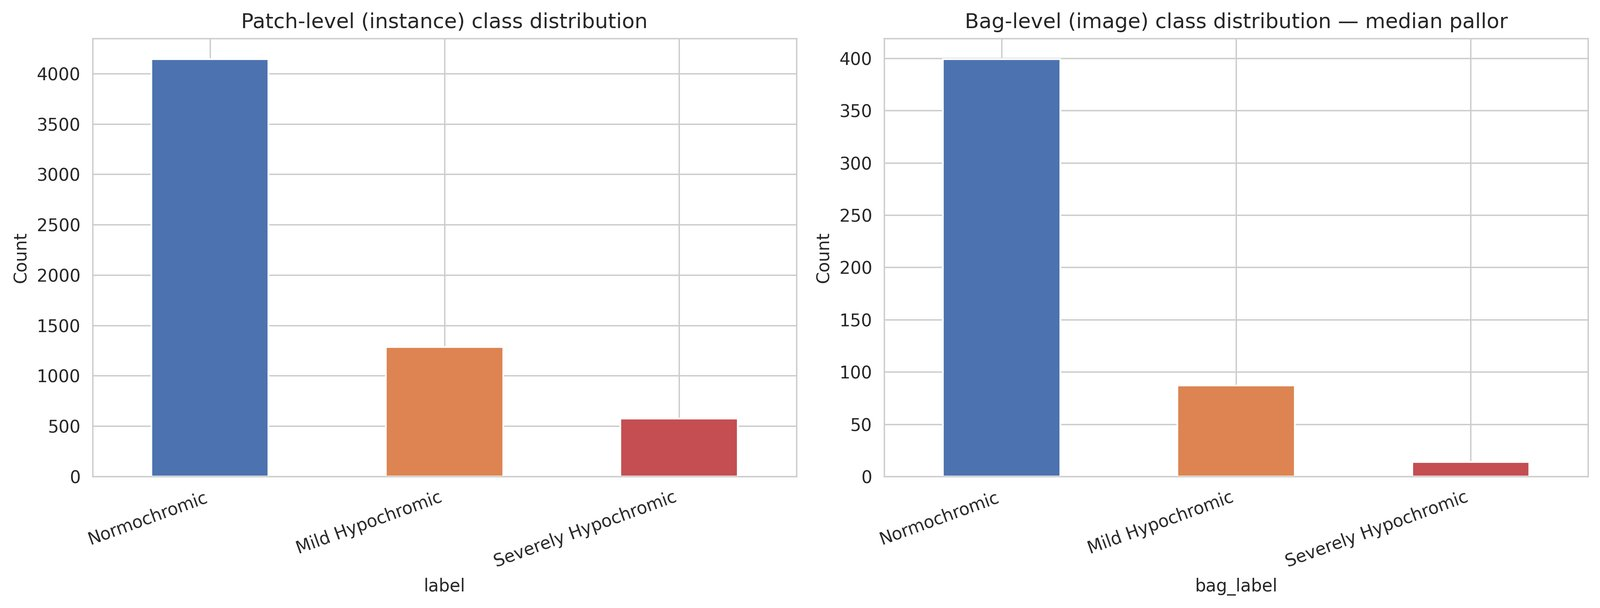

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
patch_df["label"].value_counts().reindex(CLASSES).plot(
    kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452", "#C44E52"])
axes[0].set_title("Patch-level (instance) class distribution")
axes[0].set_ylabel("Count")
axes[0].set_xticklabels([pretty(c) for c in CLASSES], rotation=20, ha="right")

bag_df["bag_label"].value_counts().reindex(CLASSES).plot(
    kind="bar", ax=axes[1], color=["#4C72B0", "#DD8452", "#C44E52"])
axes[1].set_title("Bag-level (image) class distribution — median pallor")
axes[1].set_ylabel("Count")
axes[1].set_xticklabels([pretty(c) for c in CLASSES], rotation=20, ha="right")

plt.tight_layout()
savefig("01_class_distribution.png")
plt.show()


Saved: /content/results_mil/figures/02_pallor_ratio_histogram.png


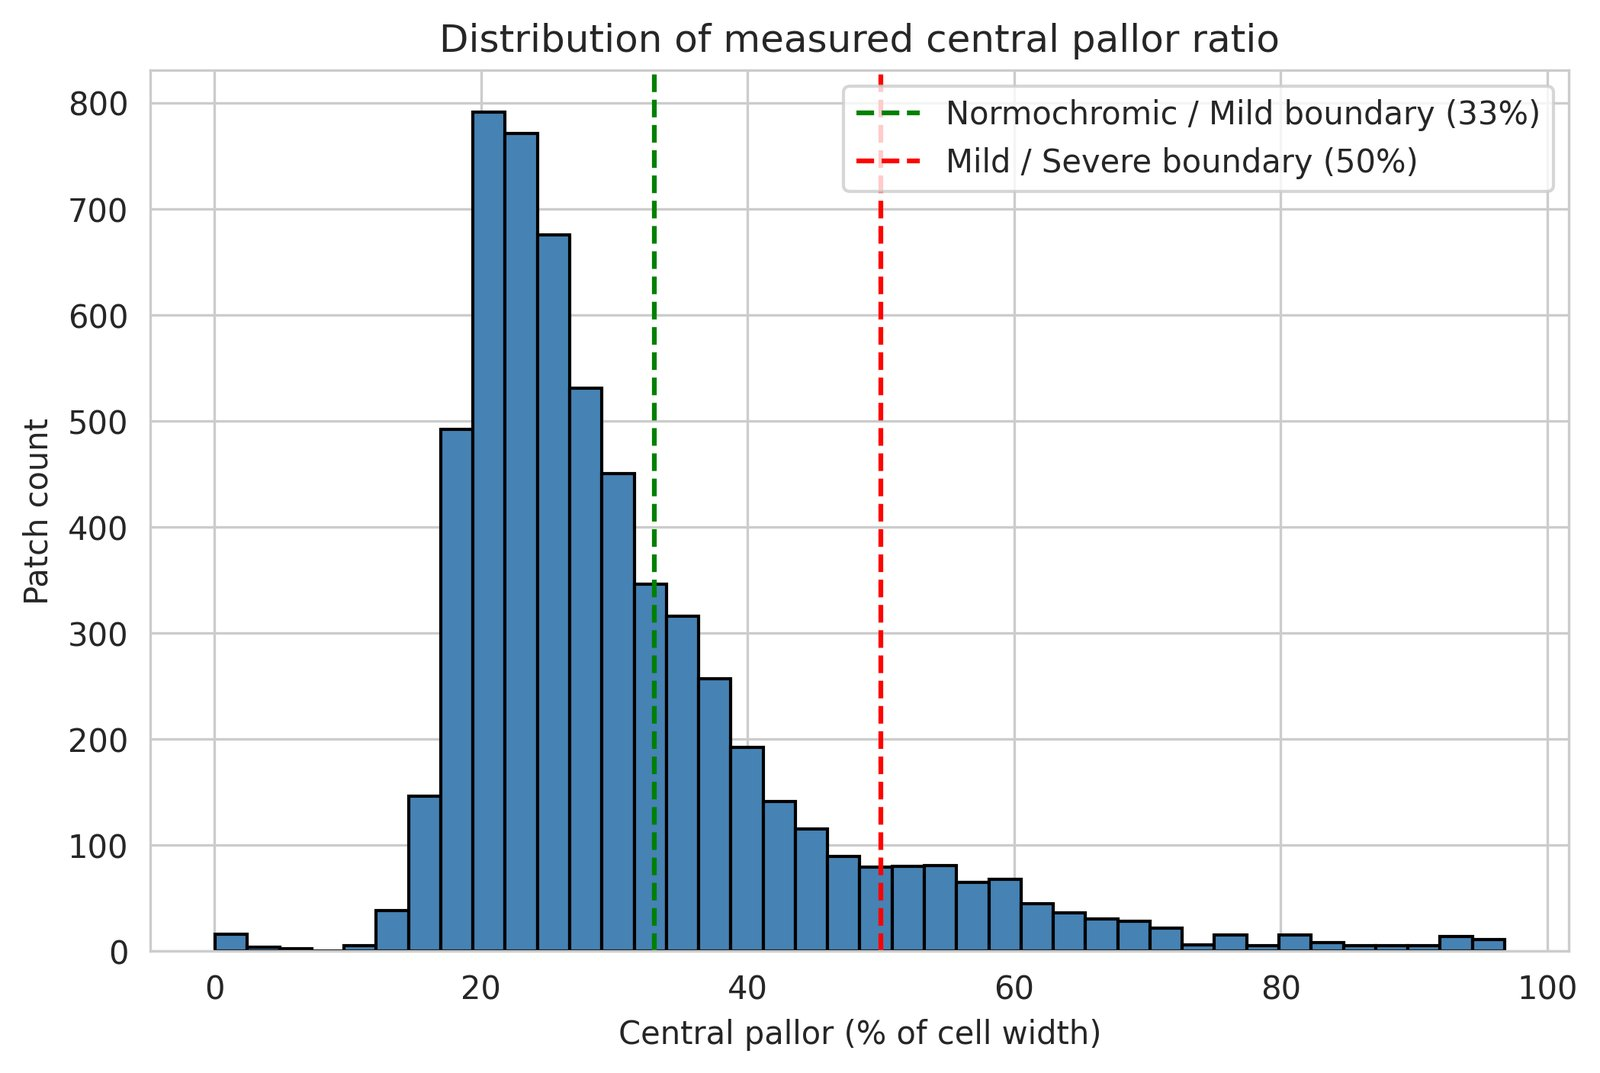

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(patch_df["pallor_ratio"], bins=40, color="steelblue", edgecolor="black")
plt.axvline(33, color="green", ls="--", label="Normochromic / Mild boundary (33%)")
plt.axvline(50, color="red", ls="--", label="Mild / Severe boundary (50%)")
plt.xlabel("Central pallor (% of cell width)")
plt.ylabel("Patch count")
plt.title("Distribution of measured central pallor ratio")
plt.legend()
savefig("02_pallor_ratio_histogram.png")
plt.show()


Saved: /content/results_mil/figures/03_samples_Normochromic.png


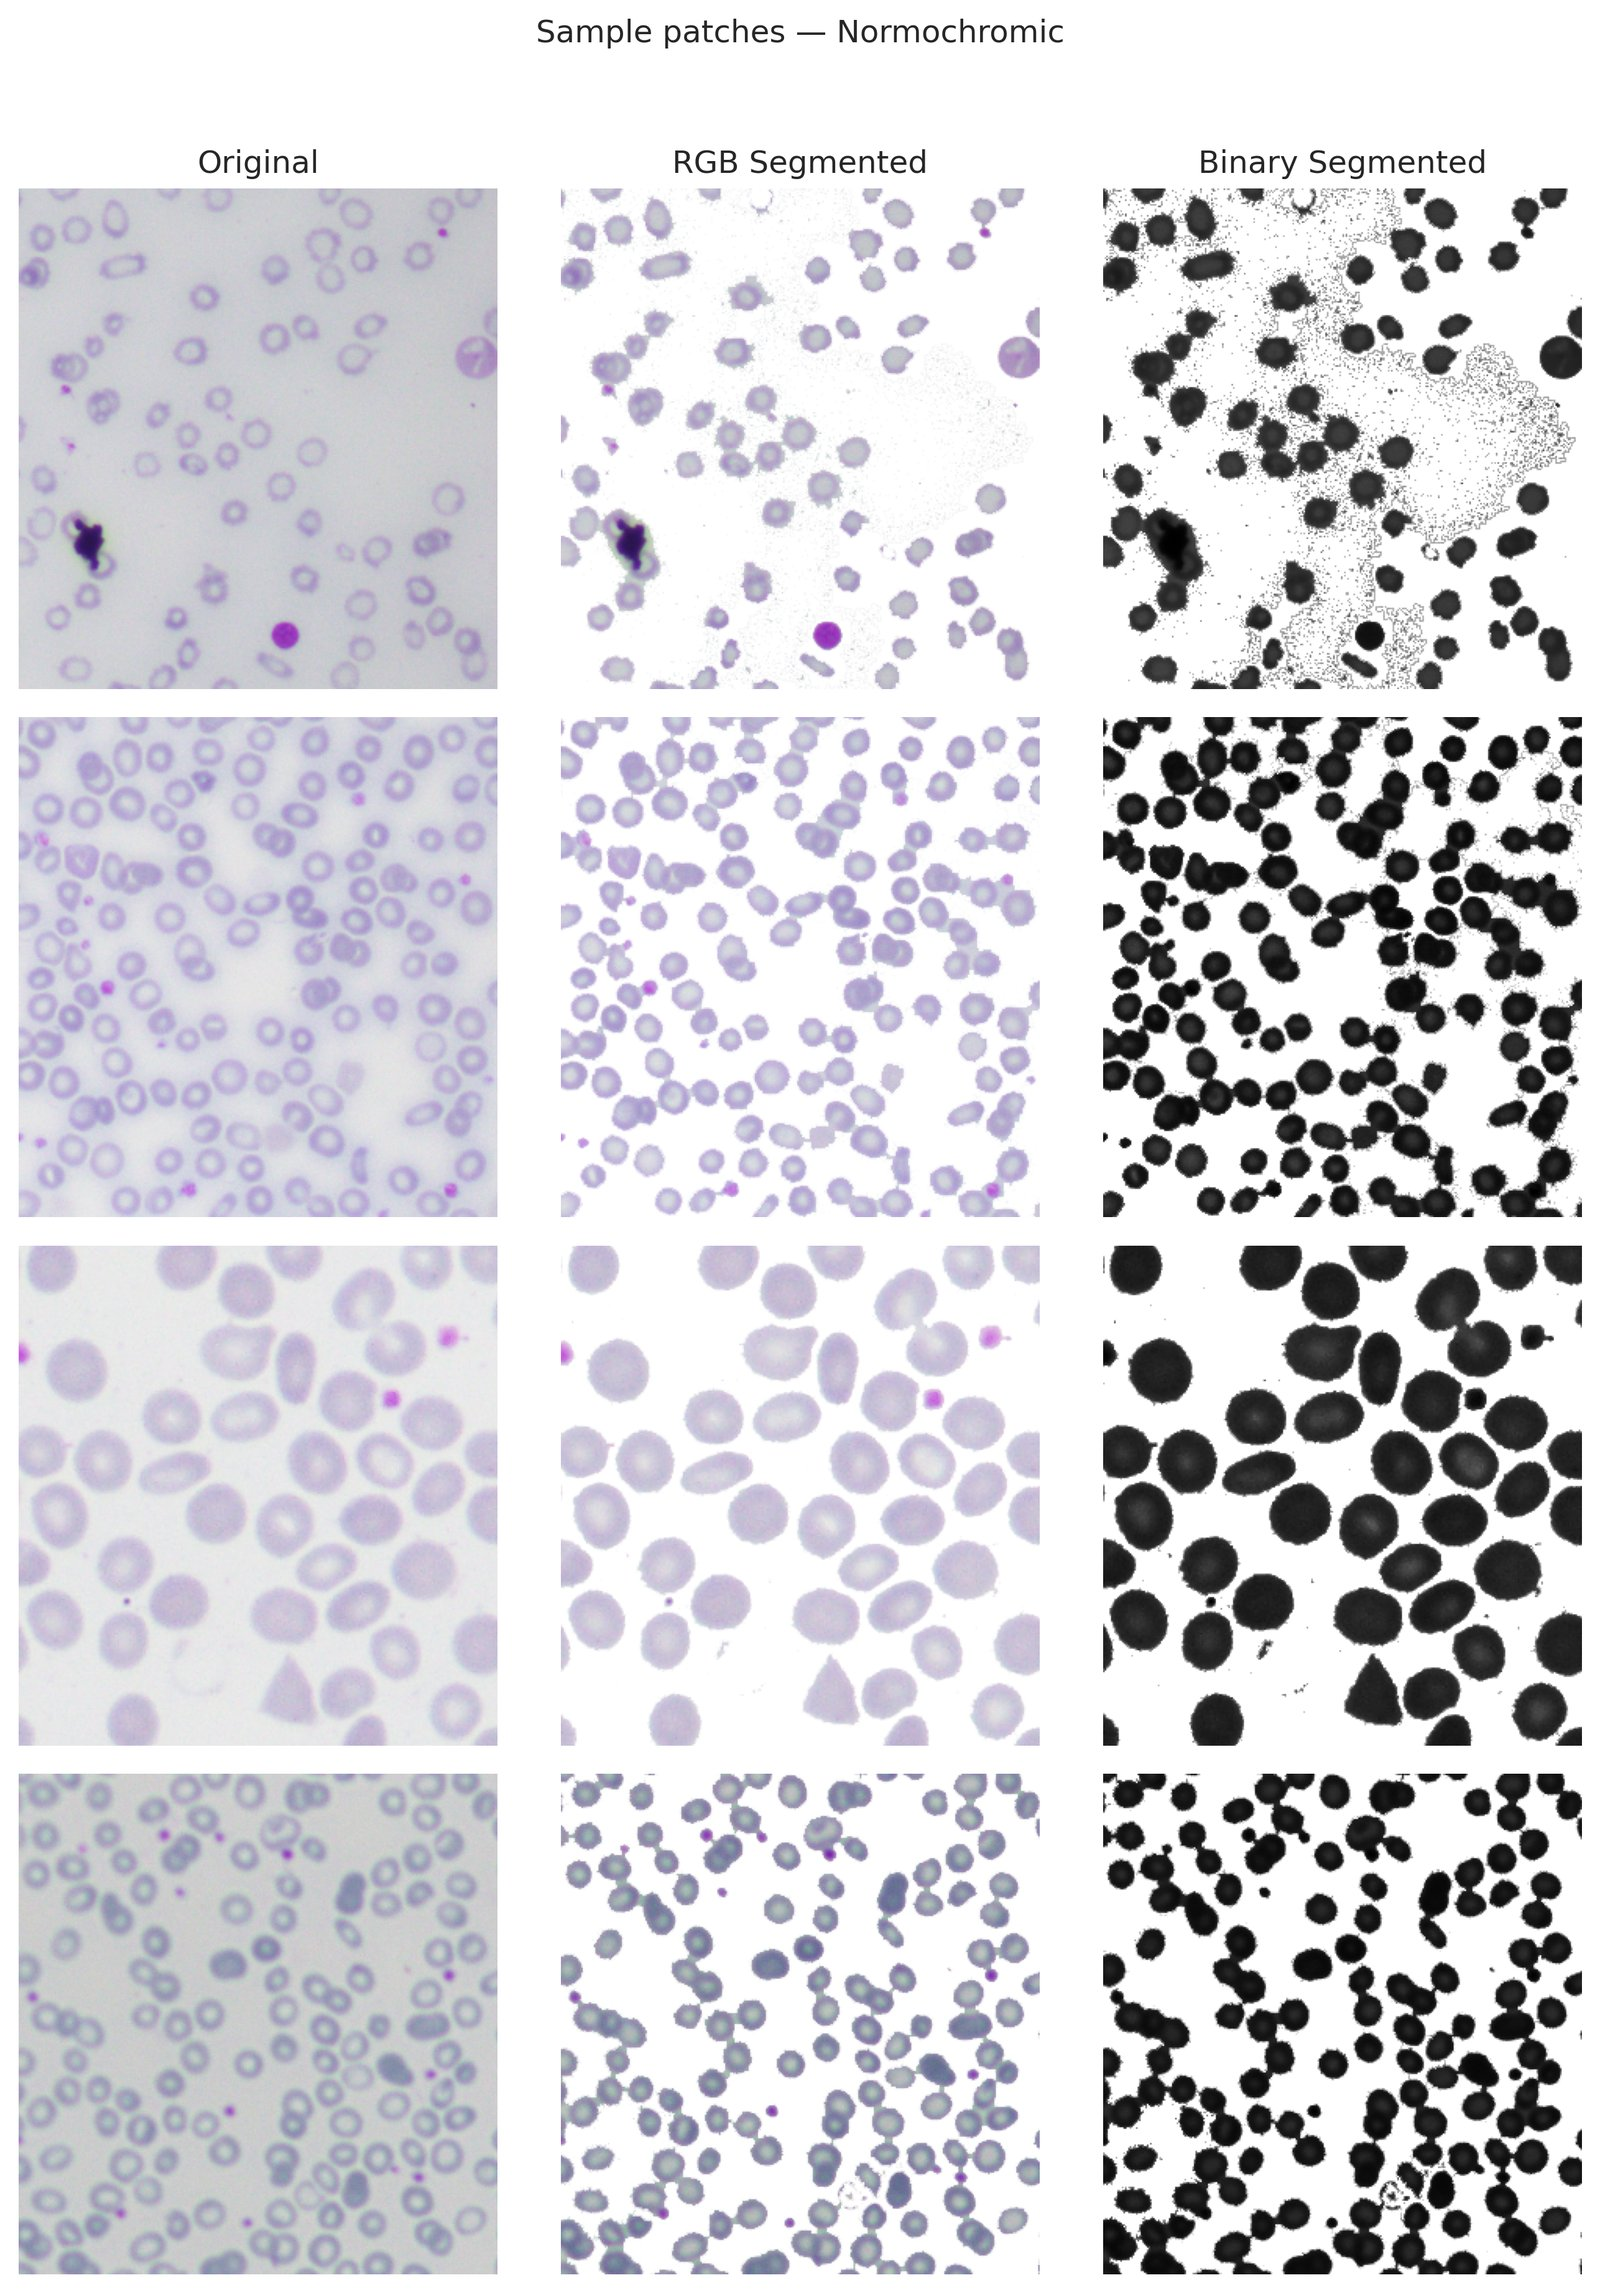

Saved: /content/results_mil/figures/03_samples_Mild_Hypochromic.png


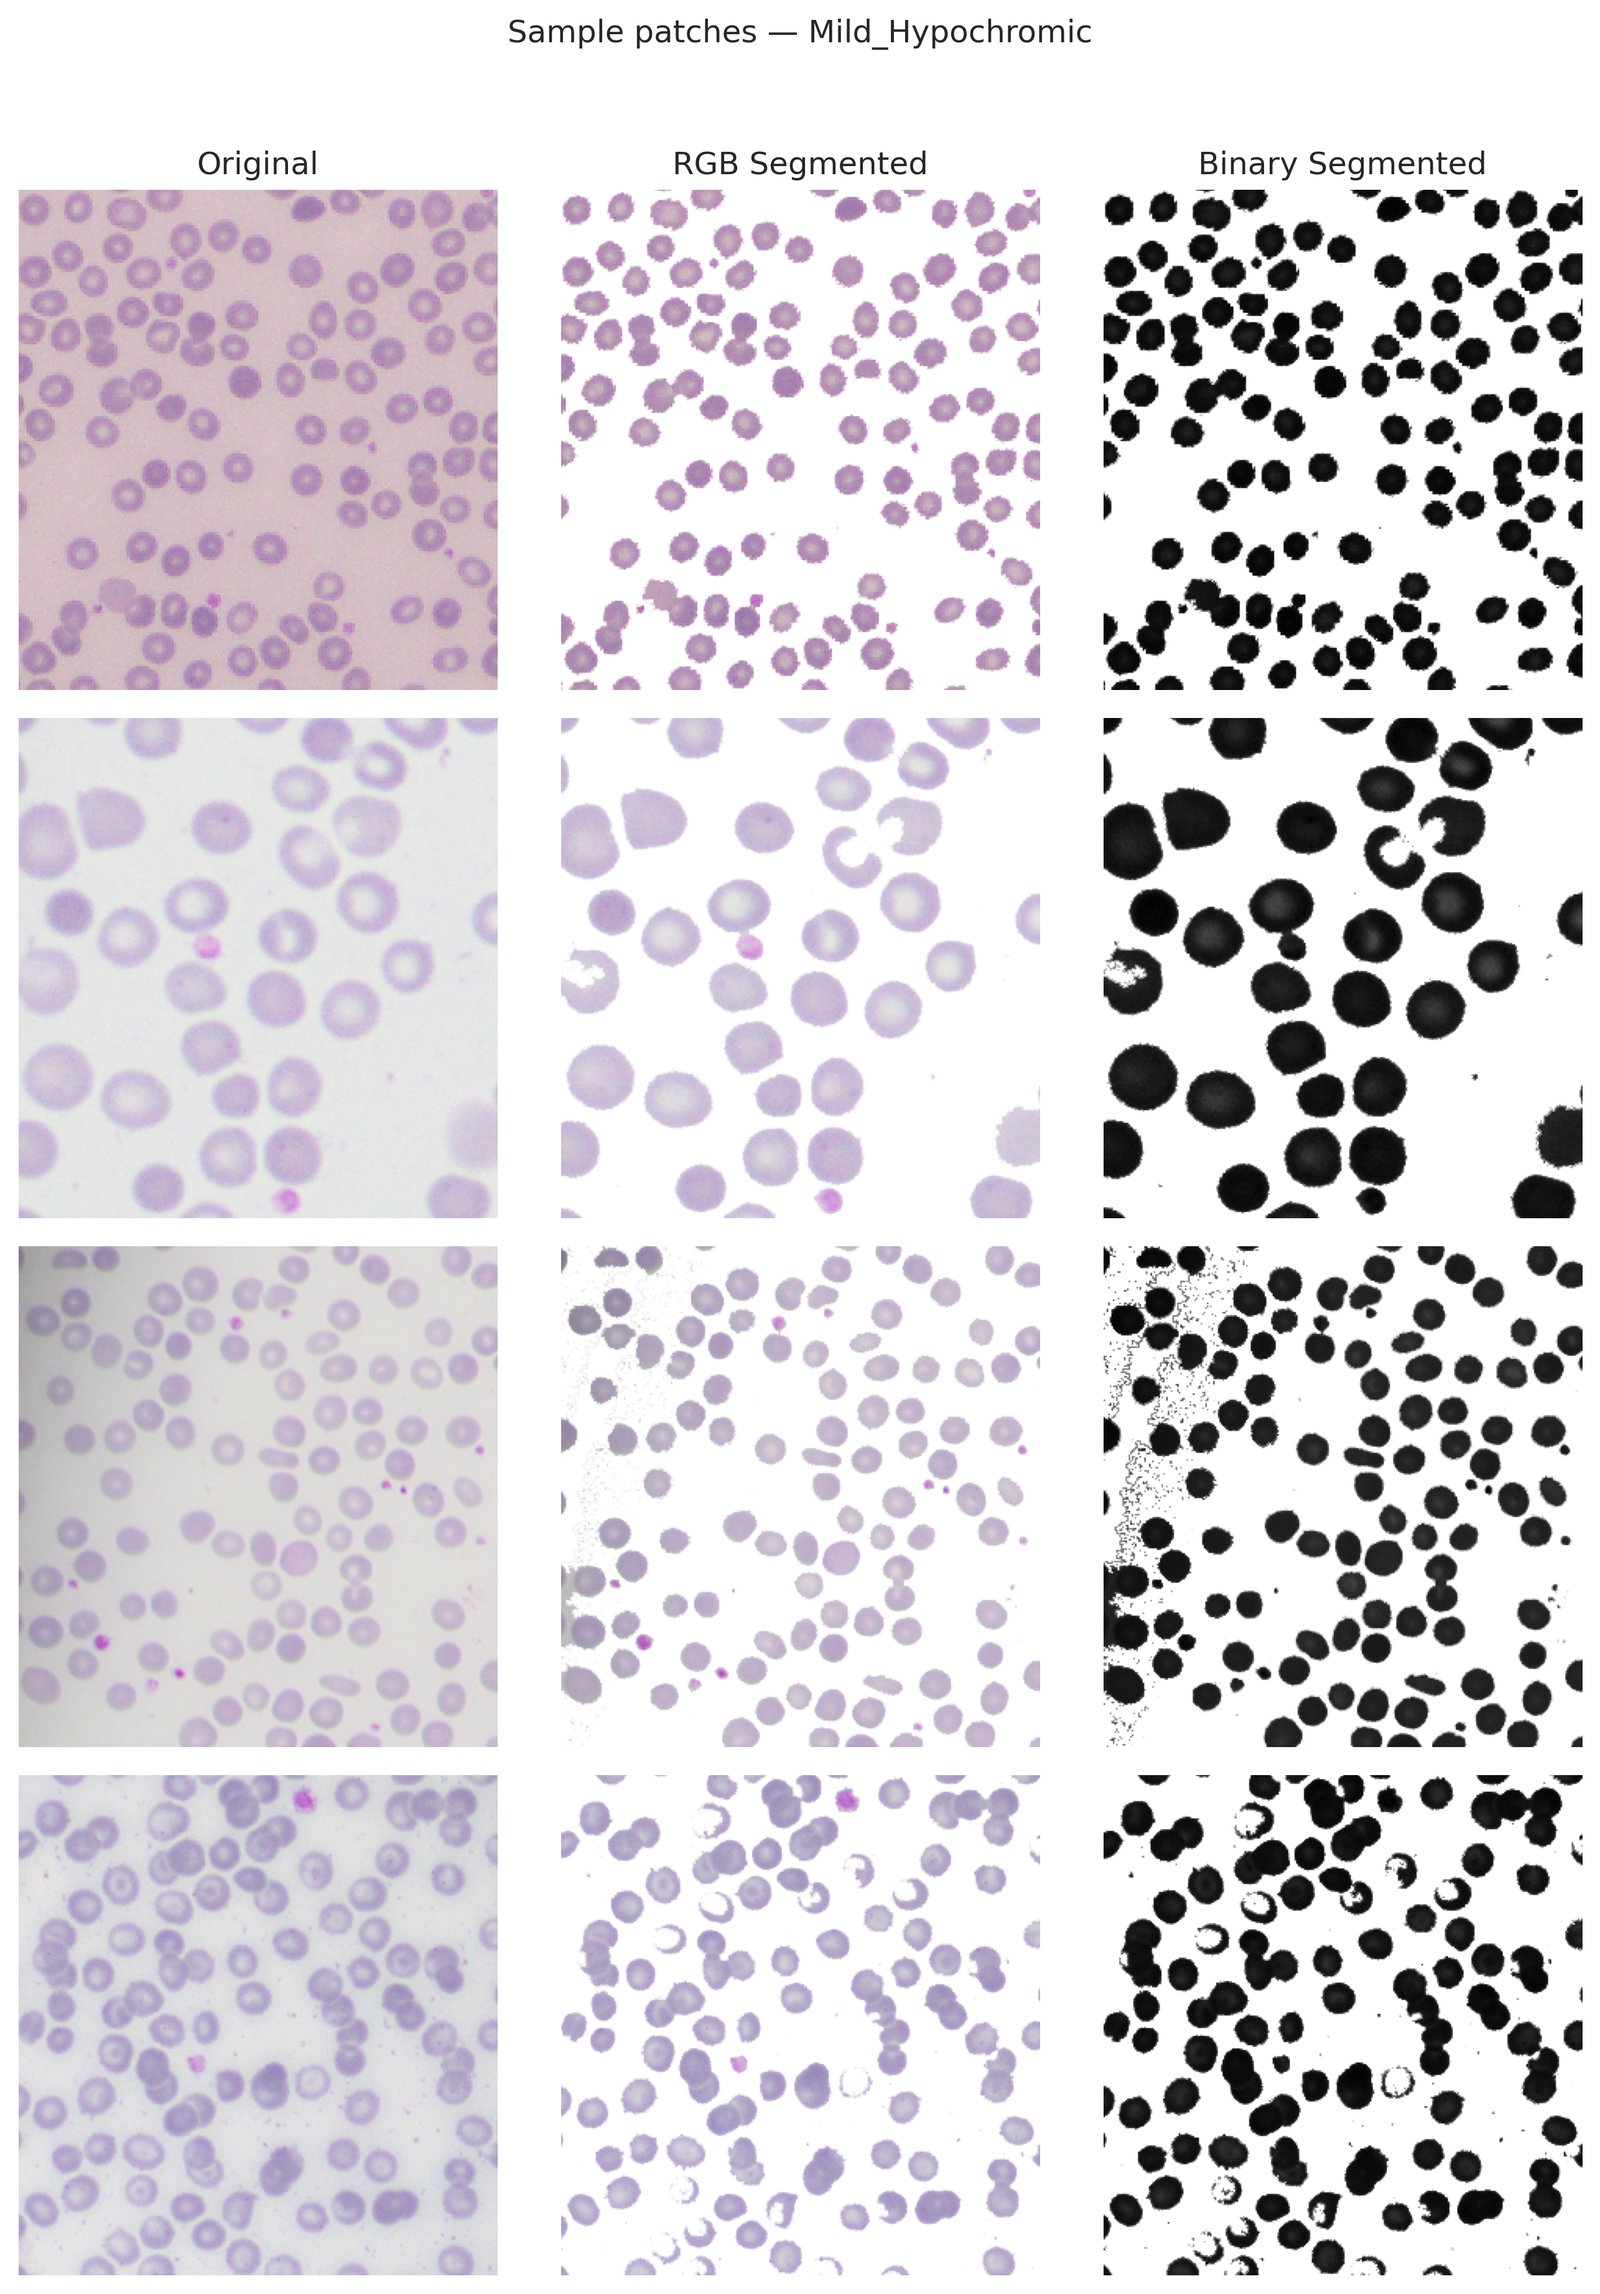

Saved: /content/results_mil/figures/03_samples_Severely_Hypochromic.png


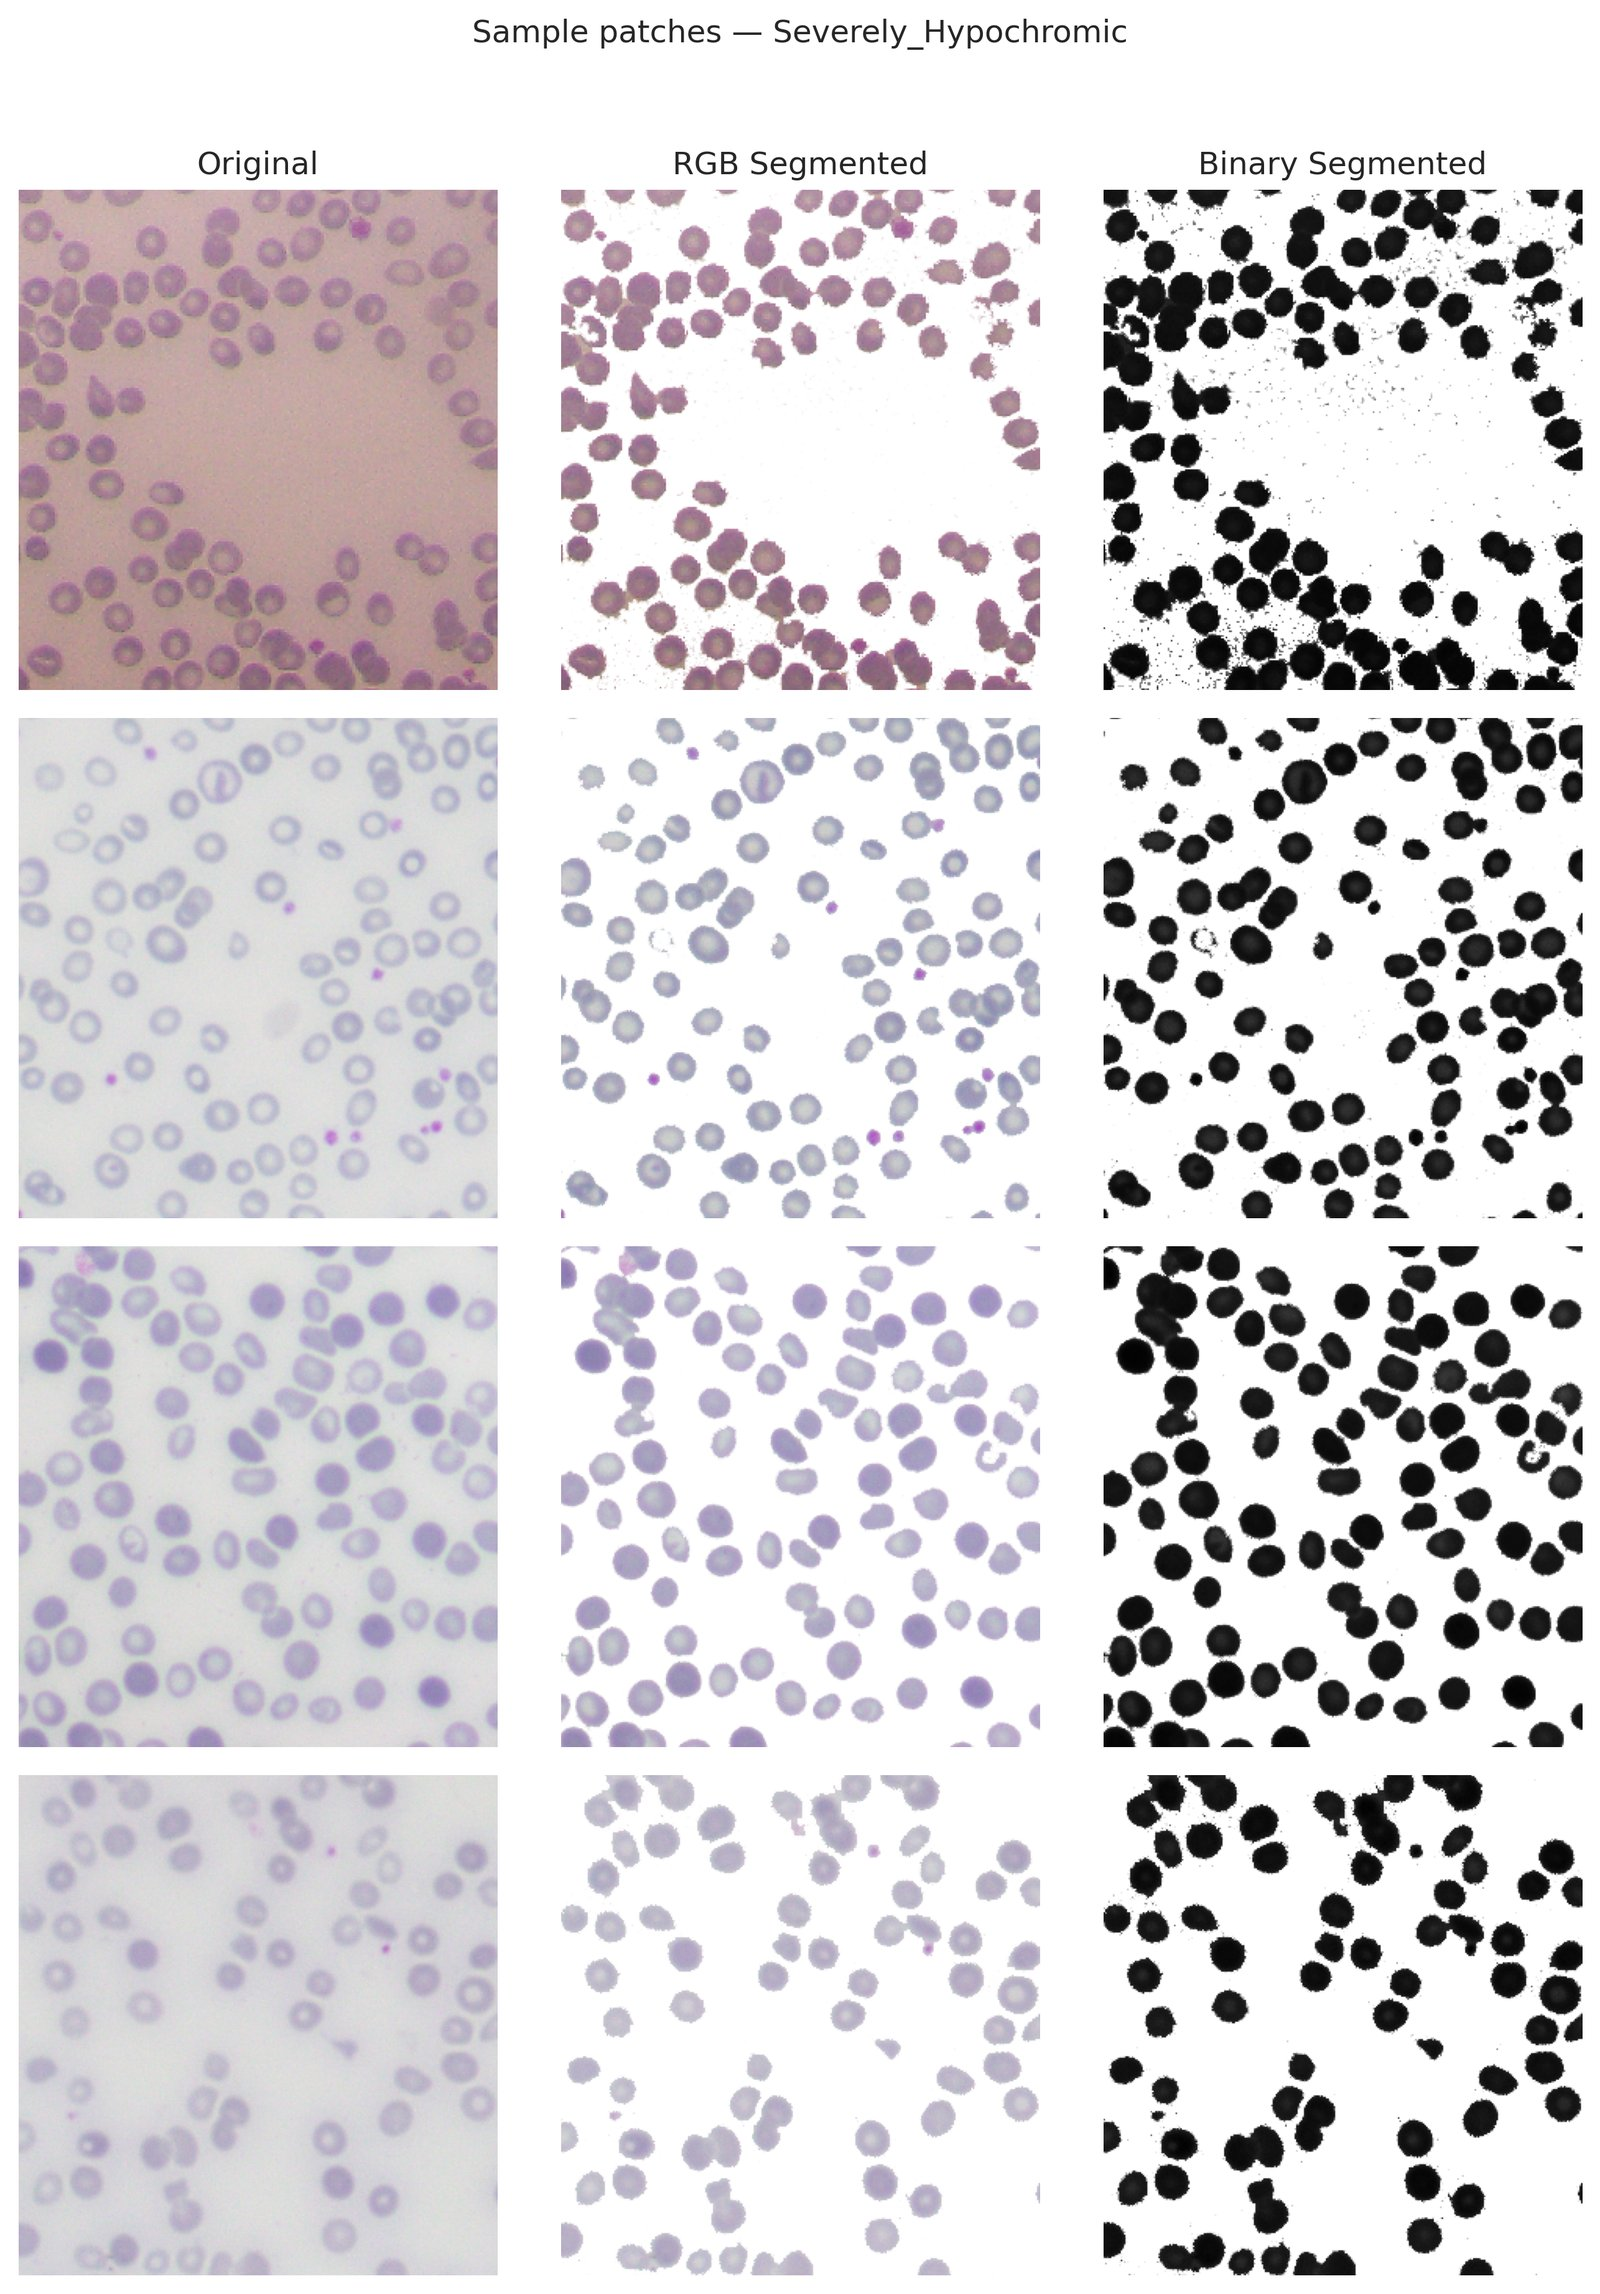

In [ ]:
def show_sample_triplets(df, label, n=4, seed=SEED):
    sub = df[df["label"] == label]
    if len(sub) == 0:
        print(f"No samples for {label}")
        return
    sub = sub.sample(min(n, len(sub)), random_state=seed)
    fig, axes = plt.subplots(len(sub), 3, figsize=(9, 3 * len(sub)))
    if len(sub) == 1:
        axes = axes.reshape(1, -1)
    for i, (_, row) in enumerate(sub.iterrows()):
        triplet = [(row["orig_path"], "Original"), (row["rgb_path"], "RGB Segmented"), (row["bin_path"], "Binary Segmented")]
        for j, (path, name) in enumerate(triplet):
            if name == "Binary Segmented":
                img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
                axes[i, j].imshow(img, cmap="gray")
            else:
                img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
                axes[i, j].imshow(img)
            axes[i, j].axis("off")
            if i == 0:
                axes[i, j].set_title(name)
        axes[i, 0].set_ylabel(f"ratio={row['pallor_ratio']:.1f}%", rotation=0, labelpad=40)
    plt.suptitle(f"Sample patches — {label}", y=1.02)
    plt.tight_layout()
    savefig(f"03_samples_{label}.png")
    plt.show()

for c in CLASSES:
    show_sample_triplets(patch_df, c)


Saved: /content/results_mil/figures/04_pallor_vs_cbc.png


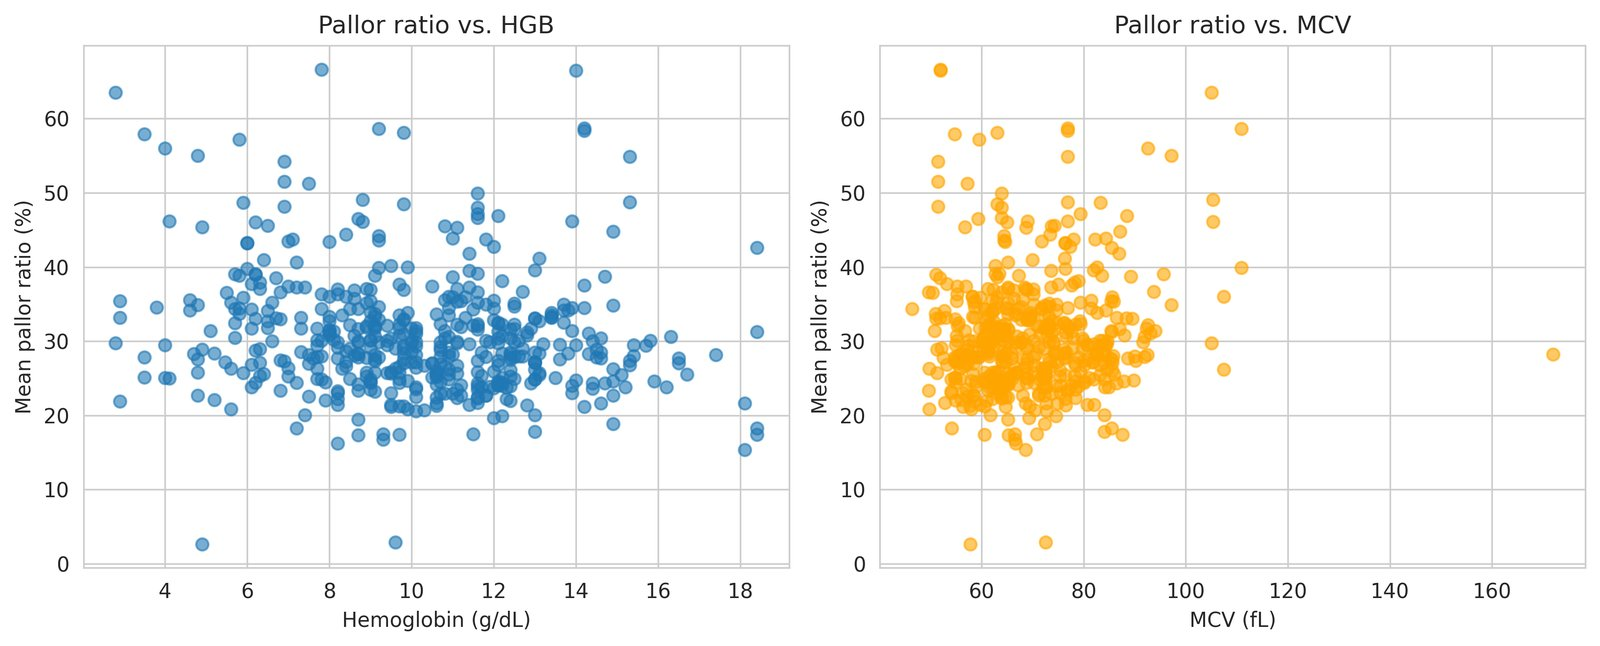

In [ ]:
img_pallor_mean = patch_df.groupby("record_id")["pallor_ratio"].mean().reset_index()
merged = img_pallor_mean.merge(cbc_df, on="record_id", how="left")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
if "HGB" in merged.columns:
    axes[0].scatter(merged["HGB"], merged["pallor_ratio"], alpha=0.6)
    axes[0].set_xlabel("Hemoglobin (g/dL)")
    axes[0].set_ylabel("Mean pallor ratio (%)")
    axes[0].set_title("Pallor ratio vs. HGB")
if "MCV" in merged.columns:
    axes[1].scatter(merged["MCV"], merged["pallor_ratio"], alpha=0.6, color="orange")
    axes[1].set_xlabel("MCV (fL)")
    axes[1].set_ylabel("Mean pallor ratio (%)")
    axes[1].set_title("Pallor ratio vs. MCV")
plt.tight_layout()
savefig("04_pallor_vs_cbc.png")
plt.show()


## 9. Train / validation / test split (bag-level)
Splitting is now trivial to do leak-free since each row *is* a bag — no grouping needed, just a
stratified split over `bag_label`.

In [ ]:
from sklearn.model_selection import train_test_split

# Every class used by the model must have enough bags to appear in train/validation/test.
counts = bag_df["bag_label"].value_counts()
print("Available bags per active class:", counts.reindex(CLASSES, fill_value=0).to_dict())

if counts.reindex(CLASSES, fill_value=0).min() < 3:
    raise RuntimeError(
        "At least 3 bags per active class are required for a train/validation/test split. "
        "Add more genuinely mild cases (recommended) rather than duplicating labels."
    )

train_bags, temp_bags = train_test_split(
    bag_df, test_size=0.30, random_state=SEED,
    stratify=bag_df["bag_label"])

val_bags, test_bags = train_test_split(
    temp_bags, test_size=0.5, random_state=SEED,
    stratify=temp_bags["bag_label"])

train_bags = train_bags.reset_index(drop=True)
val_bags   = val_bags.reset_index(drop=True)
test_bags  = test_bags.reset_index(drop=True)

print(f"Train bags: {len(train_bags)} | Val bags: {len(val_bags)} | Test bags: {len(test_bags)}")
for name, d in [("train", train_bags), ("val", val_bags), ("test", test_bags)]:
    print(name, d["bag_label"].value_counts().reindex(CLASSES, fill_value=0).to_dict())

# ------------------------------------------------------------------
# HONEST DATA-SIZE WARNING
# Under the corrected (median-based) bag_label, Severe is a genuinely rare
# class in this dataset (~14/500 bags total). A single 70/15/15 split gives
# it only ~2 val and ~2 test examples. That is not a bug to fix in code --
# it means any single-split precision/recall/F1 reported for Severe has at
# most 2-3 possible values (e.g. 0%, 50%, 100% recall on n=2) and should be
# treated as a rough signal, not a precise estimate. Flag it loudly here
# rather than let a clean-looking number hide the sample size behind it.
# ------------------------------------------------------------------
_min_class = counts.reindex(CLASSES, fill_value=0).idxmin()
_min_n = int(counts.reindex(CLASSES, fill_value=0).min())
_val_n = int(val_bags["bag_label"].value_counts().reindex(CLASSES, fill_value=0).min())
_test_n = int(test_bags["bag_label"].value_counts().reindex(CLASSES, fill_value=0).min())
print(
    f"\nWARNING: smallest class is '{_min_class}' with only {_min_n} bags total "
    f"({_val_n} in val, {_test_n} in test). Metrics for this class from a single "
    "train/val/test split will be high-variance -- see the bootstrap confidence "
    "intervals in Section 15.05 for how much to trust them, and consider stratified "
    "k-fold cross-validation (looping this split + training + evaluation over several "
    "seeds/folds and averaging) before reporting a single number in the paper."
)


Available bags per active class: {'Normochromic': 399, 'Mild_Hypochromic': 87, 'Severely_Hypochromic': 14}
Train bags: 350 | Val bags: 75 | Test bags: 75
train {'Normochromic': 279, 'Mild_Hypochromic': 61, 'Severely_Hypochromic': 10}
val {'Normochromic': 60, 'Mild_Hypochromic': 13, 'Severely_Hypochromic': 2}
test {'Normochromic': 60, 'Mild_Hypochromic': 13, 'Severely_Hypochromic': 2}



In [ ]:
print("train_bags columns:")
print(train_bags.columns.tolist())

print("\npatch_df columns:")
print(patch_df.columns.tolist())

print("\ntrain_bags sample:")
display(train_bags.head())

print("\npatch_df sample:")
display(patch_df.head())

train_bags columns:
['record_id', 'majority_label', 'max_severity_label', 'bag_label', 'mean_pallor_ratio', 'median_pallor_ratio', 'n_patches', 'WBC', 'RBC', 'HGB', 'HCT', 'MCV', 'MCH', 'MCHC', 'RDW_CV', 'PLT', 'MPV', 'NEUT_PCT', 'LYMP_PCT', 'MONO_PCT', 'EOS_PCT', 'BASO_PCT', 'NEUT_ABS', 'LYMP_ABS', 'MONO_ABS', 'EOS_ABS', 'BASO_ABS', 'rbc_morphology']

patch_df columns:
['record_id', 'patch_id', 'filename', 'orig_path', 'rgb_path', 'bin_path', 'pallor_ratio', 'label']

train_bags sample:


,record_id,majority_label,max_severity_label,bag_label,mean_pallor_ratio,median_pallor_ratio,n_patches,WBC,RBC,HGB,...,LYMP_PCT,MONO_PCT,EOS_PCT,BASO_PCT,NEUT_ABS,LYMP_ABS,MONO_ABS,EOS_ABS,BASO_ABS,rbc_morphology
0,114,Normochromic,Normochromic,Normochromic,17.430981,16.271497,12,9.55,5.79,18.4,...,18.5,17.8,0.8,0.38,5.62,1.77,1.70,0.08,0.02,Peripheral smear shows normocytic normochromic...
1,408,Normochromic,Severely_Hypochromic,Normochromic,27.684862,24.585989,12,8.05,5.50,16.5,...,40.6,7.7,1.6,0.70,3.97,3.27,0.62,0.13,0.06,Peripheral smear shows microcytic hypochromic ...
2,341,Normochromic,Mild_Hypochromic,Normochromic,26.340746,24.063674,12,6.50,4.48,5.6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Peripheral smear shows microcytic hypochromic ...
3,264,Normochromic,Mild_Hypochromic,Normochromic,27.807317,27.905382,12,3.62,2.47,3.5,...,34.3,11.3,2.8,NaN,1.87,NaN,NaN,1.24,0.00,Peripheral smear shows microcytic hypochromic ...
4,132,Normochromic,Severely_Hypochromic,Normochromic,33.696853,31.849775,12,3.70,4.78,9.1,...,67.0,14.9,5.9,0.80,0.42,2.48,0.55,0.22,0.03,Peripheral smear shows microcytic hypochromic ...



patch_df sample:


,record_id,patch_id,filename,orig_path,rgb_path,bin_path,pallor_ratio,label
0,1,1,0001_01_a.png,/content/data/anemia_500/Original_Images/0001_...,/content/data/anemia_500/RGB_Segmented/0001_01...,/content/data/anemia_500/Binary_Segmented/0001...,23.312194,Normochromic
1,1,2,0001_02_a.png,/content/data/anemia_500/Original_Images/0001_...,/content/data/anemia_500/RGB_Segmented/0001_02...,/content/data/anemia_500/Binary_Segmented/0001...,20.962214,Normochromic
2,1,3,0001_03_a.png,/content/data/anemia_500/Original_Images/0001_...,/content/data/anemia_500/RGB_Segmented/0001_03...,/content/data/anemia_500/Binary_Segmented/0001...,25.176675,Normochromic
3,1,4,0001_04_a.png,/content/data/anemia_500/Original_Images/0001_...,/content/data/anemia_500/RGB_Segmented/0001_04...,/content/data/anemia_500/Binary_Segmented/0001...,20.071170,Normochromic
4,1,5,0001_05_a.png,/content/data/anemia_500/Original_Images/0001_...,/content/data/anemia_500/RGB_Segmented/0001_05...,/content/data/anemia_500/Binary_Segmented/0001...,20.333946,Normochromic


In [ ]:
# ============================================================
# (Removed) duplicate, order-dependent dataset/dataloader block.
#
# This cell used to define its own PallorBagDataset class and build
# train_ds/val_ds/test_ds/train_loader/val_loader/test_loader here,
# referencing train_tf/eval_tf -- which are not defined until cell 33,
# further down in the notebook. On a clean top-to-bottom run this raised
# NameError: name 'train_tf' is not defined. It only appeared to work
# previously because cells had been executed out of order in the same
# Colab session, leaving train_tf in memory from an earlier run.
#
# It also used TARGET_COL = "max_severity_label" -- the same bag-labeling
# bug fixed in cell 39 (Section 7's median-based bag_label is now used
# instead).
#
# Datasets and dataloaders are now built exactly once, in cell 39
# ("RECREATE DATASETS + DATALOADERS"), which runs after train_tf/eval_tf
# (cell 33), the imputer/scaler (cell 31), and CBC_FEATURES (cell 19) all
# already exist. Nothing else in the notebook depends on this cell.
# ============================================================
print("Skipped: dataset/dataloader creation now happens once, in cell 39.")


Skipped: dataset/dataloader creation now happens once, in cell 39.


In [ ]:
# ============================================================
# (Removed) duplicate `train_ds = PallorBagDataset(train_bags, patch_df, train_tf)`.
# Same problem as cell 28: train_tf does not exist yet at this point in a
# top-to-bottom run. train_ds is created once, correctly, in cell 39.
# ============================================================
print("Skipped: train_ds is created once, in cell 39.")


Skipped: train_ds is created once, in cell 39.


In [ ]:
print("CBC_FEATURES:", CBC_FEATURES)
print("len(CBC_FEATURES):", len(CBC_FEATURES))
print("\nColumns actually in bag_df:", bag_df.columns.tolist())
print("\nMissing-fraction per column (bag_df):")
print(bag_df.isna().mean().sort_values(ascending=False))

CBC_FEATURES: ['WBC', 'RBC', 'HGB', 'HCT', 'MCV', 'MCH', 'MCHC', 'RDW_CV', 'PLT', 'MPV', 'NEUT_PCT', 'LYMP_PCT', 'MONO_PCT', 'EOS_PCT', 'BASO_PCT', 'NEUT_ABS', 'LYMP_ABS', 'MONO_ABS', 'EOS_ABS', 'BASO_ABS']
len(CBC_FEATURES): 20

Columns actually in bag_df: ['record_id', 'majority_label', 'max_severity_label', 'bag_label', 'mean_pallor_ratio', 'median_pallor_ratio', 'n_patches', 'WBC', 'RBC', 'HGB', 'HCT', 'MCV', 'MCH', 'MCHC', 'RDW_CV', 'PLT', 'MPV', 'NEUT_PCT', 'LYMP_PCT', 'MONO_PCT', 'EOS_PCT', 'BASO_PCT', 'NEUT_ABS', 'LYMP_ABS', 'MONO_ABS', 'EOS_ABS', 'BASO_ABS', 'rbc_morphology']

Missing-fraction per column (bag_df):
MONO_ABS               0.530
BASO_ABS               0.520
EOS_ABS                0.514
NEUT_ABS               0.504
LYMP_ABS               0.496
BASO_PCT               0.472
EOS_PCT                0.468
MONO_PCT               0.464
LYMP_PCT               0.460
NEUT_PCT               0.456
RDW_CV                 0.408
MPV                    0.362
MCHC                 

## 10. Tabular (CBC) feature preprocessing

In [ ]:
# Recompute CBC_FEATURES unconditionally, right here, ignoring whatever the
# global variable currently holds. Something earlier in the notebook keeps
# leaving it empty by the time execution reaches this cell -- rather than
# trust it, rebuild it fresh from bag_df/train_bags every time this cell runs.
_ALL_CBC_CANDIDATES = ["WBC", "RBC", "HGB", "HCT", "MCV", "MCH", "MCHC", "RDW_CV", "PLT", "MPV",
                       "NEUT_PCT", "LYMP_PCT", "MONO_PCT", "EOS_PCT", "BASO_PCT",
                       "NEUT_ABS", "LYMP_ABS", "MONO_ABS", "EOS_ABS", "BASO_ABS"]

CBC_FEATURES = [c for c in _ALL_CBC_CANDIDATES
                if c in train_bags.columns and not train_bags[c].isna().all()]

print("CBC_FEATURES rebuilt for this cell:", CBC_FEATURES)

if not CBC_FEATURES:
    print("\ntrain_bags columns:", train_bags.columns.tolist())
    raise RuntimeError(
        "CBC_FEATURES is still empty. None of the expected CBC column names "
        f"({_ALL_CBC_CANDIDATES}) exist in train_bags, or all of them are "
        "entirely NaN. Check the printed train_bags.columns above against "
        "this list -- the real CBC columns in your data may have different "
        "names (e.g. lowercase, or 'WBC_COUNT' instead of 'WBC')."
    )

imputer = SimpleImputer(strategy="median")
scaler  = StandardScaler()

imputer.fit(train_bags[CBC_FEATURES])
scaler.fit(imputer.transform(train_bags[CBC_FEATURES]))

import joblib
joblib.dump(imputer, f"{MODEL_DIR}/cbc_imputer.pkl")
joblib.dump(scaler, f"{MODEL_DIR}/cbc_scaler.pkl")
print("Fitted imputer/scaler on:", CBC_FEATURES)

CBC_FEATURES rebuilt for this cell: ['WBC', 'RBC', 'HGB', 'HCT', 'MCV', 'MCH', 'MCHC', 'RDW_CV', 'PLT', 'MPV', 'NEUT_PCT', 'LYMP_PCT', 'MONO_PCT', 'EOS_PCT', 'BASO_PCT', 'NEUT_ABS', 'LYMP_ABS', 'MONO_ABS', 'EOS_ABS', 'BASO_ABS']
Fitted imputer/scaler on: ['WBC', 'RBC', 'HGB', 'HCT', 'MCV', 'MCH', 'MCHC', 'RDW_CV', 'PLT', 'MPV', 'NEUT_PCT', 'LYMP_PCT', 'MONO_PCT', 'EOS_PCT', 'BASO_PCT', 'NEUT_ABS', 'LYMP_ABS', 'MONO_ABS', 'EOS_ABS', 'BASO_ABS']


## 11. MIL Bag Dataset & DataLoaders
Each `__getitem__` returns **all patches belonging to one image** stacked into a single tensor
`(N, 3, H, W)`, alongside that image's tabular CBC vector and bag label. `N` is usually 12 but the
loader tolerates fewer if some patch files are missing. Because bag size can vary, batching uses
`batch_size=1` (one bag per step) with **gradient accumulation** (`ACCUM_STEPS`) to get a stable
effective batch size without needing to pad/mask variable-length bags.

In [ ]:
# ============================================================
# 11. MIL Bag Dataset & DataLoaders
# ============================================================

class PallorBagDataset(Dataset):
    """
    Bag-level dataset for Attention MIL.

    Each item corresponds to one blood-smear image / record_id.
    All available patches belonging to that record are loaded
    and returned as a single tensor.

    Returns:
        bag_imgs : (N, 3, H, W)
        tab_vec  : (1, n_features)
        label    : scalar class index
        record_id: patient/image identifier
    """

    def __init__(self, bags_df, patch_df, transform=None):
        self.bags = bags_df.reset_index(drop=True).copy()
        self.patch_df = patch_df.copy()
        self.transform = transform

        # Group patches once for faster __getitem__
        self.patch_groups = {
            int(record_id): group.copy()
            for record_id, group in self.patch_df.groupby("record_id")
        }

        # Numeric class labels
        self.labels = self.bags["bag_label"].map(LABEL2IDX).astype(int).to_numpy()

    def __len__(self):
        return len(self.bags)

    def __getitem__(self, idx):

        bag = self.bags.iloc[idx]

        record_id = int(bag["record_id"])
        label = int(LABEL2IDX[bag["bag_label"]])

        # ----------------------------------------------------
        # Get all patches belonging to this bag
        # ----------------------------------------------------
        patches = self.patch_groups.get(record_id)

        if patches is None or len(patches) == 0:
            raise RuntimeError(
                f"No patches found for record_id={record_id}"
            )

        # Keep deterministic patch ordering
        if "patch_id" in patches.columns:
            patches = patches.sort_values("patch_id")

        # ----------------------------------------------------
        # Load image patches
        # ----------------------------------------------------
        imgs = []

        for _, row in patches.iterrows():

            img_path = row["orig_path"]

            img = cv2.imread(img_path, cv2.IMREAD_COLOR)

            if img is None:
                raise RuntimeError(
                    f"Could not read image: {img_path}"
                )

            # OpenCV BGR -> RGB
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            # Convert numpy array to PIL image for torchvision
            from PIL import Image
            img = Image.fromarray(img)

            if self.transform is not None:
                img = self.transform(img)

            imgs.append(img)

        # (N, 3, H, W)
        bag_imgs = torch.stack(imgs, dim=0)

        # ----------------------------------------------------
        # CBC / tabular features
        # ----------------------------------------------------
        tab_data = bag[CBC_FEATURES].to_numpy(dtype=np.float32).reshape(1, -1)

        # Apply the imputer and scaler fitted ONLY on training data
        tab_data = imputer.transform(tab_data)
        tab_data = scaler.transform(tab_data)

        tab_vec = torch.tensor(tab_data, dtype=torch.float32)

        return bag_imgs, tab_vec, torch.tensor(label, dtype=torch.long), record_id


# ------------------------------------------------------------
# Image transformations
# ------------------------------------------------------------

# Augmentation strengthened (RandomResizedCrop + RandomErasing added) to fight
# overfitting: with only ~350 training bags and a 28M-param backbone, the
# previous Resize-only pipeline let the model memorize exact patch layouts.
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0), ratio=(0.9, 1.1)),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.08,
        hue=0.02
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),

    transforms.RandomErasing(p=0.25, scale=(0.02, 0.10)),
])


eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


print("PallorBagDataset defined.")
print("Training transform defined.")
print("Evaluation transform defined.")

PallorBagDataset defined.
Training transform defined.
Evaluation transform defined.


## 12. ConvNeXt encoder + gated attention MIL + tabular fusion

**Per-patch encoder**: `convnext_tiny` (ImageNet-pretrained) turns each of the `N` patches in a bag
into a feature vector, giving an `(N, D)` instance-feature matrix `H`.

**Gated attention pooling** (Ilse et al., 2018): learns a scalar attention weight `a_k` per patch,

```
V_k = tanh(W_v · H_k)
U_k = sigmoid(W_u · H_k)
a_k = softmax_k( w^T (V_k ⊙ U_k) )
Z   = Σ_k a_k · H_k
```

`Z` is the resulting bag-level embedding — a weighted combination of patch features where the
weights themselves are learned end-to-end, and where the gating (`sigmoid` branch) lets the network
suppress uninformative patches non-linearly rather than just via a plain softmax attention.

**Tabular branch**: small MLP over the CBC features, one vector per bag (patient).

**Fusion classifier**: `Z` concatenated with the tabular embedding → MLP → 3-class bag prediction.

The `a_k` weights are kept around after the forward pass (`self.last_attention`) purely for
visualization in Section 16 — they tell you which patches the model actually leaned on.

In [ ]:
class GatedAttentionMIL(nn.Module):
    def __init__(self, in_dim, hidden_dim=256):
        super().__init__()
        self.V = nn.Linear(in_dim, hidden_dim)
        self.U = nn.Linear(in_dim, hidden_dim)
        self.w = nn.Linear(hidden_dim, 1)

    def forward(self, H):
        # H: (N, in_dim) instance features for one bag -> returns (in_dim,), (N,) attention weights
        A_V = torch.tanh(self.V(H))
        A_U = torch.sigmoid(self.U(H))
        scores = self.w(A_V * A_U).squeeze(-1)      # (N,)
        weights = torch.softmax(scores, dim=0)       # (N,)
        Z = (weights.unsqueeze(-1) * H).sum(dim=0)    # (in_dim,)
        return Z, weights


class ConvNeXtAttentionMIL(nn.Module):
    def __init__(self, n_classes=2, n_tab_features=10, pretrained=True,
                 freeze_backbone_up_to=FREEZE_BACKBONE_UP_TO):
        super().__init__()
        self.backbone = timm.create_model("convnext_tiny", pretrained=pretrained, num_classes=0)
        img_feat_dim = self.backbone.num_features

        self.attention_pool = GatedAttentionMIL(img_feat_dim, hidden_dim=256)

        self.tab_mlp = nn.Sequential(
    nn.Linear(n_tab_features, 64), nn.ReLU(), nn.LayerNorm(64), nn.Dropout(0.4),
    nn.Linear(64, 32), nn.ReLU(),
)

        # Dropout raised (0.4->0.5, plus a new bag-embedding dropout below):
        # train accuracy was reaching ~95-97% while val loss kept climbing,
        # the textbook signature of a classifier head memorizing ~350 bags.
        self.embedding_dropout = nn.Dropout(0.3)  # applied to the pooled bag embedding Z
        self.classifier = nn.Sequential(
            nn.Linear(img_feat_dim + 32, 128), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(128, n_classes),
        )

        self.last_attention = None  # (N,) weights from the most recent forward pass

        # ------------------------------------------------------------
        # Partial backbone freezing.
        # Fully fine-tuning all of ConvNeXt-Tiny (~28M params) on ~350
        # training bags with batch size 1 destroys the pretrained features
        # within a single epoch (this is what caused the previous run's
        # collapse to a constant prediction). Freezing the stem and early
        # stages keeps the general-purpose low-level features intact and
        # only adapts the last stage, which holds the higher-level features
        # most relevant to a new domain.
        # ------------------------------------------------------------
        self._freeze_backbone(freeze_backbone_up_to)

    def _freeze_backbone(self, up_to_stage):
        for p in self.backbone.stem.parameters():
            p.requires_grad = False
        for i, stage in enumerate(self.backbone.stages):
            trainable = i >= up_to_stage
            for p in stage.parameters():
                p.requires_grad = trainable
        n_trainable = sum(p.numel() for p in self.backbone.parameters() if p.requires_grad)
        n_total = sum(p.numel() for p in self.backbone.parameters())
        print(f"Backbone: {n_trainable:,} / {n_total:,} params trainable "
              f"(stem + stages[0:{up_to_stage}] frozen, stages[{up_to_stage}:] trainable)")

    def backbone_trainable_parameters(self):
        return [p for p in self.backbone.parameters() if p.requires_grad]

    def head_parameters(self):
        return (list(self.attention_pool.parameters())
                + list(self.tab_mlp.parameters())
                + list(self.classifier.parameters()))

    def forward(self, bag_imgs, tab_vec):
    # bag_imgs: (N, 3, H, W)

        H = self.backbone(bag_imgs)

        Z, weights = self.attention_pool(H)
        self.last_attention = weights.detach()
        Z = self.embedding_dropout(Z)

    # Ensure tabular tensor is 2D: (1, n_features)
        tab_vec = tab_vec.reshape(1, -1)

        tab_feat = self.tab_mlp(tab_vec)

        fused = torch.cat(
        [Z.unsqueeze(0), tab_feat],
        dim=1
    )

        return self.classifier(fused)


model = ConvNeXtAttentionMIL(n_classes=len(CLASSES), n_tab_features=len(CBC_FEATURES)).to(device)
n_params = sum(p.numel() for p in model.parameters())
n_trainable_total = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {n_params:,} | Trainable: {n_trainable_total:,}")


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Backbone: 15,472,128 / 27,820,128 params trainable (stem + stages[0:3] frozen, stages[3:] trainable)
Total parameters: 28,320,580 | Trainable: 15,972,580


## 13. Training (bag-level, class-balanced loss, cosine LR schedule, early stopping,
gradient accumulation)

In [ ]:
# CRITICAL FIX: this used to read train_ds.labels, but train_ds is not
# created until the "RECREATE DATASETS + DATALOADERS" cell, which runs
# AFTER this cell. Compute the class distribution directly from
# train_bags["bag_label"] instead -- no forward dependency on a later cell.
_train_labels = train_bags["bag_label"].map(LABEL2IDX).to_numpy()

present_classes = np.unique(_train_labels)
missing_classes = [CLASSES[i] for i in range(len(CLASSES)) if i not in present_classes]
if missing_classes:
    raise RuntimeError(f"Classes missing from training split: {missing_classes}")

# Full inverse-frequency weighting (the "balanced" option) overcorrects on
# this dataset: Severe (n=10) gets ~28x the weight of Normochromic (n=278), which
# pushes the model to over-predict the rare classes -- seen as 23% of true
# Normochromic bags being misclassified as Mild in the confusion matrix. Soften
# with sqrt of inverse frequency instead: still upweights rare classes,
# just less aggressively, so the decision boundary isn't dragged as far.
class_counts_train = np.bincount(_train_labels, minlength=len(CLASSES))
inv_freq = 1.0 / class_counts_train
soft_weights = np.sqrt(inv_freq)
soft_weights = soft_weights / soft_weights.sum() * len(CLASSES)  # renormalize to a comparable scale
class_weights = torch.tensor(soft_weights, dtype=torch.float32).to(device)
print("Class counts (train):", dict(zip(CLASSES, class_counts_train)))
print("Softened class weights (sqrt inverse-frequency):", dict(zip(CLASSES, class_weights.cpu().numpy())))

# LABEL_SMOOTHING and WEIGHT_DECAY now come from the config cell (Section 2)
# instead of being hardcoded here a second time, so the two definitions can't
# drift out of sync (both were raised there to fight overfitting).
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=LABEL_SMOOTHING)

optimizer = torch.optim.AdamW([
    {"params": model.backbone_trainable_parameters(), "lr": BACKBONE_LR},
    {"params": model.head_parameters(), "lr": HEAD_LR},
], weight_decay=WEIGHT_DECAY)

_warmup = torch.optim.lr_scheduler.LinearLR(
    optimizer, start_factor=0.1, total_iters=max(WARMUP_EPOCHS, 1))
_cosine = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=max(EPOCHS - WARMUP_EPOCHS, 1))
scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer, schedulers=[_warmup, _cosine], milestones=[WARMUP_EPOCHS])


def run_epoch(loader, train_mode):
    model.train() if train_mode else model.eval()
    total_loss, total_correct, total_n = 0.0, 0, 0
    epoch_preds, epoch_labels = [], []
    if train_mode:
        optimizer.zero_grad()

    with torch.set_grad_enabled(train_mode):
        for step, (bag_imgs, tab, label, _) in enumerate(loader):
            bag_imgs = bag_imgs.squeeze(0).to(device)
            tab = tab.squeeze(0).to(device)
            label = label.to(device)

            out = model(bag_imgs, tab)
            loss = criterion(out, label)

            if train_mode:
                (loss / ACCUM_STEPS).backward()
                if (step + 1) % ACCUM_STEPS == 0:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
                    optimizer.step()
                    optimizer.zero_grad()

            total_loss += loss.item()
            pred = out.argmax(1)
            total_correct += (pred == label).sum().item()
            total_n += 1
            epoch_preds.append(pred.item())
            epoch_labels.append(label.item())

        if train_mode and total_n % ACCUM_STEPS != 0:
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            optimizer.step()
            optimizer.zero_grad()

    avg_loss = total_loss / max(total_n, 1)
    acc = total_correct / max(total_n, 1)
    macro_f1 = f1_score(epoch_labels, epoch_preds, average="macro", zero_division=0)
    return avg_loss, acc, macro_f1

print("run_epoch(), optimizer (differential LR), and warmup+cosine scheduler are ready.")

Class counts (train): {'Normochromic': np.int64(279), 'Mild_Hypochromic': np.int64(61), 'Severely_Hypochromic': np.int64(10)}
Softened class weights (sqrt inverse-frequency): {'Normochromic': np.float32(0.35626566), 'Mild_Hypochromic': np.float32(0.7619231), 'Severely_Hypochromic': np.float32(1.8818113)}
run_epoch(), optimizer (differential LR), and warmup+cosine scheduler are ready.


In [ ]:
# ============================================================
# (Removed) duplicate run_epoch() definition.
# This cell used to redefine run_epoch() a second time, silently
# overriding the version from the previous cell and discarding its
# gradient clipping and gradient accumulation. The version defined above
# (cell 37) is now the single, canonical run_epoch() used for training.
# ============================================================
print("Using the single run_epoch() defined above (gradient clipping + accumulation enabled).")


Using the single run_epoch() defined above (gradient clipping + accumulation enabled).


In [ ]:
# ============================================================
# RECREATE DATASETS + DATALOADERS
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

from PIL import Image
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler


# ============================================================
# LABEL MAPPING
# ============================================================
# CRITICAL FIX: do NOT redefine CLASSES/LABEL2IDX here. Cell 17 already
# builds these dynamically from the bags that actually exist (e.g. it
# drops "Normochromic" entirely if no normochromic bags exist). Hardcoding a
# fixed 3-class mapping here risked silently mismatching the model's
# output layer if the active class set ever changed.
assert "CLASSES" in globals() and "LABEL2IDX" in globals(), \
    "CLASSES / LABEL2IDX must already be defined by cell 17 before this cell runs."
print("Using classes from cell 17:", CLASSES)

# CRITICAL FIX: this used to be "max_severity_label", which silently
# reintroduced the exact bug Section 7 (cell 17) fixed -- one severe-looking
# patch forcing an entire bag to "Severe". Training on that label is why
# the model collapsed to predicting a single class. Train on "bag_label"
# (the median-severity label from cell 17) instead.
TARGET_COL = "bag_label"


# ============================================================
# TABULAR FEATURES
# ============================================================
# CBC_FEATURES already reflects the column-drop NaN cleaning from cell 19
# (any CBC column with missing values was dropped there) -- reuse it
# instead of a separate hardcoded list that could go stale.
TABULAR_COLS = CBC_FEATURES


# ============================================================
# DATASET
# ============================================================

class PallorBagDataset(Dataset):

    def __init__(
        self,
        bags_df,
        patch_df,
        transform=None
    ):

        self.bags_df = bags_df.reset_index(drop=True).copy()
        self.patch_df = patch_df.copy()
        self.transform = transform

        # Labels
        self.labels = np.array([
            LABEL2IDX[x]
            for x in self.bags_df[TARGET_COL]
        ], dtype=np.int64)

        # Group patches by record_id
        self.patch_groups = {
            record_id: group.reset_index(drop=True)
            for record_id, group
            in self.patch_df.groupby("record_id")
        }


    def __len__(self):
        return len(self.bags_df)


    def __getitem__(self, idx):

        bag = self.bags_df.iloc[idx]

        record_id = bag["record_id"]

        # ----------------------------------------------------
        # Label
        # ----------------------------------------------------

        label = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        # ----------------------------------------------------
        # Tabular features
        # ----------------------------------------------------
        # CRITICAL FIX: this used to fill NaN with 0.0 and pass raw,
        # unnormalized CBC values (WBC in the thousands next to
        # percentages 0-100) straight into a linear layer, skipping the
        # imputer/scaler fitted in Section 10 entirely. Reuse that fitted
        # imputer + scaler instead, exactly like the original dataset class
        # (cell 33) did, so every feature is on a comparable scale.

        tab_raw = bag[TABULAR_COLS].to_numpy(dtype=np.float32).reshape(1, -1)
        tab_raw = imputer.transform(tab_raw)
        tab_raw = scaler.transform(tab_raw)

        tab = torch.tensor(
            tab_raw.squeeze(0),
            dtype=torch.float32
        )

        # ----------------------------------------------------
        # Images
        # ----------------------------------------------------

        if record_id not in self.patch_groups:

            raise ValueError(
                f"No patches found for record_id={record_id}"
            )

        patches = self.patch_groups[record_id]

        images = []

        for _, patch in patches.iterrows():

            image_path = patch["rgb_path"]

            if pd.isna(image_path):
                raise ValueError(
                    f"Missing image path for record_id={record_id}"
                )

            if not os.path.exists(image_path):
                raise FileNotFoundError(
                    f"Image not found:\n{image_path}"
                )

            image = Image.open(
                image_path
            ).convert("RGB")

            if self.transform is not None:
                image = self.transform(image)

            images.append(image)

        bag_imgs = torch.stack(images)

        # IMPORTANT:
        # run_epoch() expects:
        # bag_imgs, tab, label, _
        return (
            bag_imgs,
            tab,
            label,
            record_id
        )


# ============================================================
# CHECK TRANSFORMS
# ============================================================

if "train_tf" not in globals():

    from torchvision import transforms

    train_tf = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),
        transforms.RandomRotation(15),
        transforms.ColorJitter(
            brightness=0.15,
            contrast=0.15,
            saturation=0.10,
            hue=0.02
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    eval_tf = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])


# ============================================================
# CREATE DATASETS
# ============================================================

train_ds = PallorBagDataset(
    train_bags,
    patch_df,
    train_tf
)

val_ds = PallorBagDataset(
    val_bags,
    patch_df,
    eval_tf
)

test_ds = PallorBagDataset(
    test_bags,
    patch_df,
    eval_tf
)


# ============================================================
# CHECK CLASS DISTRIBUTION
# ============================================================

class_counts = np.bincount(
    train_ds.labels,
    minlength=len(CLASSES)
)

print("Training class distribution:")

for i, count in enumerate(class_counts):
    print(
        f"{i}: {CLASSES[i]} = {count}"
    )


# ============================================================
# WEIGHTED SAMPLER
# ============================================================

# Same softening as the loss weights above: full 1/count oversampling would
# show the model the 10 Severe bags as often as the 278 Normochromic bags every
# epoch -- too aggressive for a dataset this imbalanced. sqrt(1/count)
# still oversamples rare classes, just less extremely.
sample_weights = np.array([
    1.0 / np.sqrt(class_counts[label])
    for label in train_ds.labels
])

sampler = WeightedRandomSampler(
    weights=torch.tensor(
        sample_weights,
        dtype=torch.double
    ),
    num_samples=len(train_ds),
    replacement=True
)


# ============================================================
# DATALOADERS
# ============================================================

train_loader = DataLoader(
    train_ds,
    batch_size=1,
    sampler=sampler,
    num_workers=0
)

val_loader = DataLoader(
    val_ds,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_ds,
    batch_size=1,
    shuffle=False,
    num_workers=0
)


# ============================================================
# TEST
# ============================================================

bag_imgs, tab, label, record_id = next(
    iter(train_loader)
)

print("\nDataLoader test successful:")
print("Bag images:", bag_imgs.shape)
print("Tabular:", tab.shape)
print("Label:", label)
print("Record ID:", record_id)

print("\ntrain_loader:", len(train_loader))
print("val_loader:", len(val_loader))
print("test_loader:", len(test_loader))

print("\nSUCCESS: train_loader, val_loader and test_loader are ready.")


Using classes from cell 17: ['Normochromic', 'Mild_Hypochromic', 'Severely_Hypochromic']
Training class distribution:
0: Normochromic = 279
1: Mild_Hypochromic = 61
2: Severely_Hypochromic = 10

DataLoader test successful:
Bag images: torch.Size([1, 12, 3, 224, 224])
Tabular: torch.Size([1, 20])
Label: tensor([0])
Record ID: tensor([104])

train_loader: 350
val_loader: 75
test_loader: 75

SUCCESS: train_loader, val_loader and test_loader are ready.


In [ ]:
# ============================================================
# CHECK WHICH DATA VARIABLES STILL EXIST
# ============================================================

required = [
    "train_bags",
    "val_bags",
    "test_bags",
    "patch_df"
]

print("Checking required variables...\n")

for name in required:
    if name in globals():
        obj = globals()[name]
        print(f"✓ {name}: exists | shape = {getattr(obj, 'shape', 'N/A')}")
    else:
        print(f"✗ {name}: MISSING")

print("\nOther relevant variables:")

for name in [
    "bags_df",
    "train_df",
    "val_df",
    "test_df",
    "LABEL2IDX",
    "train_tf",
    "eval_tf",
    "model",
    "optimizer",
    "criterion",
    "scheduler",
    "device"
]:
    print(
        f"{'✓' if name in globals() else '✗'} {name}"
    )

Checking required variables...

✓ train_bags: exists | shape = (350, 28)
✓ val_bags: exists | shape = (75, 28)
✓ test_bags: exists | shape = (75, 28)
✓ patch_df: exists | shape = (6000, 8)

Other relevant variables:
✗ bags_df
✗ train_df
✗ val_df
✗ test_df
✓ LABEL2IDX
✓ train_tf
✓ eval_tf
✓ model
✓ optimizer
✓ criterion
✓ scheduler
✓ device


In [ ]:
# NOTE: EPOCHS is intentionally NOT redefined here. It must stay equal to
# the value set once in the config cell (cell 5), because the warmup +
# cosine scheduler built in cell 37 already used that value for its
# T_max/milestones. Redefining EPOCHS here (it used to say `EPOCHS = 22`
# while the scheduler was built assuming EPOCHS = 30) meant the cosine
# decay never finished by the last epoch actually trained.
assert "EPOCHS" in globals(), "EPOCHS must already be defined by cell 5."
print(f"Training for EPOCHS={EPOCHS} (WARMUP_EPOCHS={WARMUP_EPOCHS}), as set in cell 5.")

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "val_macro_f1": []
}

best_val_f1 = -1.0
best_val_loss = float("inf")
_epochs_no_improve = 0  # early-stopping counter, tracked on val_loss


for epoch in range(1, EPOCHS + 1):

    tr_loss, tr_acc, _ = run_epoch(
        train_loader,
        train_mode=True
    )

    va_loss, va_acc, va_f1 = run_epoch(
        val_loader,
        train_mode=False
    )

    scheduler.step()


    # --------------------------------------------------------
    # Store history
    # --------------------------------------------------------

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(va_acc)
    history["val_macro_f1"].append(va_f1)


    # --------------------------------------------------------
    # Track best validation loss
    # --------------------------------------------------------

    if va_loss < best_val_loss - 1e-4:
        best_val_loss = va_loss
        _epochs_no_improve = 0
    else:
        _epochs_no_improve += 1


    # --------------------------------------------------------
    # Track best validation macro-F1
    # --------------------------------------------------------

    improved = va_f1 > best_val_f1

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train_loss={tr_loss:.4f} "
        f"acc={tr_acc:.4f} | "
        f"val_loss={va_loss:.4f} "
        f"acc={va_acc:.4f} "
        f"macro_f1={va_f1:.4f}"
        f"{'  -> new best (macro-F1)' if improved else ''}"
    )


    # --------------------------------------------------------
    # Save best model based on validation macro-F1
    # --------------------------------------------------------

    if improved:

        best_val_f1 = va_f1

        torch.save(
            model.state_dict(),
            f"{MODEL_DIR}/best_convnext_attention_mil.pt"
        )

    # --------------------------------------------------------
    # Early stopping on val_loss.
    # Reinstated: without this, the loss-curve plot in Section 14 shows
    # train_loss gliding down to ~0.4 for 15-20 epochs after val_loss has
    # already stopped improving -- a long overfitting tail that makes the
    # curve look worse (and less trustworthy) than the actual best
    # checkpoint. Stopping once val_loss stalls for EARLY_STOP_PATIENCE
    # epochs keeps the plotted curve honest about where learning actually
    # stopped, without changing which checkpoint gets saved (that's still
    # whichever epoch had the best val macro-F1).
    # --------------------------------------------------------
    if _epochs_no_improve >= EARLY_STOP_PATIENCE:
        print(
            f"\nEarly stopping at epoch {epoch}: val_loss has not improved "
            f"for {EARLY_STOP_PATIENCE} epochs (best val_loss={best_val_loss:.4f})."
        )
        break


# ============================================================
# SAVE TRAINING HISTORY
# ============================================================

pd.DataFrame(history).to_csv(
    f"{TABLES_DIR}/training_history.csv",
    index=False
)


print(
    f"\nTraining complete — ran {len(history['train_loss'])}/{EPOCHS} epochs "
    f"({'stopped early' if len(history['train_loss']) < EPOCHS else 'used full budget'}). "
    f"Best val macro-F1: {best_val_f1:.4f} "
    f"(best val loss seen: {best_val_loss:.4f})."
)

Training for EPOCHS=30 (WARMUP_EPOCHS=3), as set in cell 5.
Epoch 01/30 | train_loss=1.2325 acc=0.4429 | val_loss=1.1354 acc=0.7733 macro_f1=0.3840  -> new best (macro-F1)
Epoch 02/30 | train_loss=1.0345 acc=0.6800 | val_loss=1.1245 acc=0.7200 macro_f1=0.4451  -> new best (macro-F1)
Epoch 03/30 | train_loss=0.9714 acc=0.7457 | val_loss=1.0835 acc=0.7067 macro_f1=0.4594  -> new best (macro-F1)
Epoch 04/30 | train_loss=0.8898 acc=0.7829 | val_loss=1.3698 acc=0.5200 macro_f1=0.4930  -> new best (macro-F1)


## 14. Training / validation curves (300 dpi)

In [ ]:
epochs_ran = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(epochs_ran, history["train_loss"], label="Train loss", marker="o", ms=3)
axes[0].plot(epochs_ran, history["val_loss"], label="Val loss", marker="o", ms=3)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].set_title("Loss curves"); axes[0].legend()

axes[1].plot(epochs_ran, history["train_acc"], label="Train accuracy", marker="o", ms=3)
axes[1].plot(epochs_ran, history["val_acc"], label="Val accuracy", marker="o", ms=3)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy curves"); axes[1].legend()

axes[2].plot(epochs_ran, history["val_macro_f1"], label="Val macro-F1",
             marker="o", ms=3, color="#55A868")
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Macro F1")
axes[2].set_title("Validation macro-F1 (checkpoint criterion)"); axes[2].legend()

plt.tight_layout()
savefig("05_training_curves.png")
plt.show()


## 15. Test-set evaluation (bag/image level — no post-hoc aggregation needed)

In [ ]:
model.load_state_dict(torch.load(f"{MODEL_DIR}/best_convnext_attention_mil.pt", map_location=device))
model.eval()

# ---- Test-time augmentation (TTA) ----
# RBC patches have no canonical orientation, so averaging predictions over the
# original bag plus horizontal/vertical/both-flipped versions is a "free"
# accuracy/recall improvement: no extra training, no extra labels, just 4x
# inference compute.
TTA_FLIPS = [None, [3], [2], [2, 3]]

all_probs, all_preds, all_labels, all_rids, all_attn = [], [], [], [], []
with torch.no_grad():
    for bag_imgs, tab, label, rid in tqdm(test_loader, desc="Testing (with TTA)"):
        bag_imgs = bag_imgs.squeeze(0).to(device)
        tab = tab.to(device)

        tta_probs = []
        base_weights = None
        for dims in TTA_FLIPS:
            aug_imgs = torch.flip(bag_imgs, dims=dims) if dims else bag_imgs
            out = model(aug_imgs, tab)
            tta_probs.append(torch.softmax(out, dim=1).cpu().numpy()[0])
            if dims is None:
                base_weights = model.last_attention.cpu().numpy()

        probs = np.mean(tta_probs, axis=0)
        pred = probs.argmax()

        all_probs.append(probs)
        all_preds.append(pred)
        all_labels.append(label.item())
        all_rids.append(rid.item())
        # Attention weights are taken from the un-flipped pass for visualization.
        all_attn.append(base_weights)

all_probs = np.stack(all_probs, axis=0)
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

test_acc = accuracy_score(all_labels, all_preds)
test_f1_macro = f1_score(all_labels, all_preds, average="macro")
print(f"Test accuracy: {test_acc:.4f} | Macro F1: {test_f1_macro:.4f}")

report = classification_report(all_labels, all_preds, labels=list(range(len(CLASSES))),
                                target_names=[pretty(c) for c in CLASSES], digits=4, zero_division=0)
print(report)
with open(f"{TABLES_DIR}/bag_level_classification_report.txt", "w") as f:
    f.write(report)


### 15.05 Additional imbalance-aware metrics

Accuracy alone can look fine while the minority (Mild) class is barely being recognized. These
extra metrics are all sensitive to that failure mode in a way plain accuracy is not:
balanced accuracy (mean per-class recall), Matthews correlation coefficient, Cohen's kappa, and
per-class recall.


In [ ]:
balanced_acc = balanced_accuracy_score(all_labels, all_preds)
mcc = matthews_corrcoef(all_labels, all_preds)
kappa = cohen_kappa_score(all_labels, all_preds)
per_class_recall = recall_score(all_labels, all_preds, labels=list(range(len(CLASSES))),
                                 average=None, zero_division=0)

print("Balanced accuracy :", round(float(balanced_acc), 4))
print("Matthews corrcoef :", round(float(mcc), 4))
print("Cohen's kappa      :", round(float(kappa), 4))
print("\nPer-class recall:")
for c, r in zip(CLASSES, per_class_recall):
    print(f"  {pretty(c):<28} {r:.4f}")

# ------------------------------------------------------------------
# Bootstrap 95% confidence intervals.
# The test set has as few as 2 examples for the rarest class (see the
# warning printed at the train/val/test split). A point estimate alone
# hides that -- resample the test predictions with replacement 2000x to
# show the actual uncertainty range for each metric, rather than reporting
# a single number that looks more precise than the sample size supports.
# ------------------------------------------------------------------
N_BOOTSTRAP = 2000
rng = np.random.default_rng(SEED if "SEED" in globals() else 0)
n_test = len(all_labels)

boot_bal_acc, boot_macro_f1, boot_mcc = [], [], []
for _ in range(N_BOOTSTRAP):
    idx = rng.integers(0, n_test, size=n_test)
    yb, pb = all_labels[idx], all_preds[idx]
    if len(np.unique(yb)) < 2:
        continue  # a resample that lost an entire class isn't a valid confusion matrix
    boot_bal_acc.append(balanced_accuracy_score(yb, pb))
    boot_macro_f1.append(f1_score(yb, pb, average="macro", zero_division=0))
    boot_mcc.append(matthews_corrcoef(yb, pb))

def ci(vals):
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return float(lo), float(hi)

bal_acc_ci = ci(boot_bal_acc)
macro_f1_ci = ci(boot_macro_f1)
mcc_ci = ci(boot_mcc)

print(f"\nBootstrap 95% CI ({len(boot_bal_acc)}/{N_BOOTSTRAP} valid resamples, n_test={n_test}):")
print(f"  Balanced accuracy : {bal_acc_ci[0]:.4f} - {bal_acc_ci[1]:.4f}")
print(f"  Macro F1          : {macro_f1_ci[0]:.4f} - {macro_f1_ci[1]:.4f}")
print(f"  Matthews corrcoef : {mcc_ci[0]:.4f} - {mcc_ci[1]:.4f}")
print(
    "\nReport these intervals alongside the point estimates in the paper -- "
    "a wide interval is expected given the class sizes and is more honest "
    "than the point estimate alone."
)

extra_metrics = {
    "balanced_accuracy": float(balanced_acc),
    "balanced_accuracy_95ci": bal_acc_ci,
    "matthews_corrcoef": float(mcc),
    "matthews_corrcoef_95ci": mcc_ci,
    "macro_f1_95ci": macro_f1_ci,
    "cohen_kappa": float(kappa),
    "per_class_recall": {c: float(r) for c, r in zip(CLASSES, per_class_recall)},
    "n_bootstrap_valid": len(boot_bal_acc),
}
with open(f"{TABLES_DIR}/extra_test_metrics.json", "w") as f:
    json.dump(extra_metrics, f, indent=2)


### 15.1 Confusion matrix heatmap

In [ ]:
cm = confusion_matrix(all_labels, all_preds, labels=list(range(len(CLASSES))))
cm_norm = cm.astype("float") / np.clip(cm.sum(axis=1, keepdims=True), 1, None)

# Wrap the (now longer) class names onto multiple short lines so neighboring
# tick labels never overlap, and keep rotation at 0 since the wrapped text is
# already short per line.
tick_labels = [wrap_label(c) for c in CLASSES]

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=tick_labels, yticklabels=tick_labels,
            annot_kws={"size": 11}, ax=axes[0])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True"); axes[0].set_title("Confusion matrix (counts)")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=tick_labels, yticklabels=tick_labels,
            annot_kws={"size": 11}, ax=axes[1])
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True"); axes[1].set_title("Confusion matrix (row-normalized)")

for ax in axes:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0, ha="center", fontsize=9)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, va="center", fontsize=9)

plt.tight_layout()
savefig("06_confusion_matrix.png")
plt.show()


### 15.2 ROC curves (one-vs-rest) and Precision–Recall curves

In [ ]:
y_bin = label_binarize(all_labels, classes=list(range(len(CLASSES))))
if len(CLASSES) == 2:
    # sklearn quirk: label_binarize collapses to a single column for binary problems.
    y_bin = np.hstack([1 - y_bin, y_bin])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for i, c in enumerate(CLASSES):
    if y_bin[:, i].sum() == 0:
        print(f"Skipping ROC for '{c}': no positive samples in the test set.")
        continue
    fpr, tpr, _ = roc_curve(y_bin[:, i], all_probs[:, i])
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, label=f"{pretty(c)} (AUC={roc_auc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC curves (one-vs-rest)"); axes[0].legend()

for i, c in enumerate(CLASSES):
    if y_bin[:, i].sum() == 0:
        continue
    prec, rec, _ = precision_recall_curve(y_bin[:, i], all_probs[:, i])
    ap = average_precision_score(y_bin[:, i], all_probs[:, i])
    axes[1].plot(rec, prec, label=f"{pretty(c)} (AP={ap:.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision–Recall curves"); axes[1].legend()

plt.tight_layout()
savefig("07_roc_pr_curves.png")
plt.show()


## 13.5 Stratified K-Fold Cross-Validation (pooled, honest evaluation)

The single 70/15/15 split above is convenient but fragile: the test set has only 2
Severe bags and 13 Mild bags, so the confusion matrix and ROC/PR curves for those
classes are built from a handful of points. That is what produces the zero-count
cells and blocky, stair-step ROC curves in Sections 15.1/15.2 — it is a genuine
small-sample-size artifact, not something a code fix alone can make disappear
(with only 14 Severe bags in the whole dataset, no single split will ever give a
smooth curve for that class).

The fix here is **5-fold stratified cross-validation with early stopping**: the
model is retrained from scratch 5 times, each time holding out a different 20% of
the 500 bags as that fold's test set. Every bag ends up in exactly one fold's
held-out test set, so pooling the out-of-fold (OOF) predictions across all 5 folds
gives a confusion matrix and ROC/PR curves built from **all 500 bags** instead of
75 — including all 14 Severe bags instead of 2. This also gives an honest estimate
of generalization performance (averaged over 5 different splits) instead of a
result that depends on which 75 bags happened to land in the one test set.

The imputer/scaler and the class-balancing weights are refit independently inside
each fold's training data only, so there is no leakage across folds. Each fold
also uses the same regularization and early-stopping settings introduced above.
This section is additive — it does not change the single-split model, checkpoint,
or Grad-CAM visualizations used later in the notebook; it only produces a second,
more statistically honest set of confusion-matrix / ROC / PR / training-curve
figures for the paper.

In [ ]:
import copy
from sklearn.model_selection import StratifiedKFold

bag_df_cv = bag_df.reset_index(drop=True).copy()
y_cv = bag_df_cv["bag_label"].to_numpy()
rid_to_pos = {int(rid): pos for pos, rid in enumerate(bag_df_cv["record_id"])}

oof_probs = np.zeros((len(bag_df_cv), len(CLASSES)), dtype=np.float32)
oof_preds = np.full(len(bag_df_cv), -1, dtype=np.int64)
oof_labels = bag_df_cv["bag_label"].map(LABEL2IDX).to_numpy()
fold_of = np.full(len(bag_df_cv), -1, dtype=np.int64)
fold_histories = []

# Save the single-split imputer/scaler so they can be restored afterwards --
# every downstream cell (Grad-CAM, export, etc.) still uses the single-split
# model/imputer/scaler defined earlier in the notebook.
_single_split_imputer, _single_split_scaler = imputer, scaler

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

for fold_idx, (trainval_idx, test_idx) in enumerate(skf.split(bag_df_cv, y_cv), start=1):
    print(f"\n{'='*60}\nFOLD {fold_idx}/{N_FOLDS}\n{'='*60}")

    trainval_df = bag_df_cv.iloc[trainval_idx].reset_index(drop=True)
    fold_test_df = bag_df_cv.iloc[test_idx].reset_index(drop=True)
    fold_of[test_idx] = fold_idx

    fold_train_df, fold_val_df = train_test_split(
        trainval_df, test_size=0.15, random_state=SEED,
        stratify=trainval_df["bag_label"])
    fold_train_df = fold_train_df.reset_index(drop=True)
    fold_val_df = fold_val_df.reset_index(drop=True)

    # Fold-local imputer/scaler, fit ONLY on this fold's training bags.
    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()
    imputer.fit(fold_train_df[CBC_FEATURES])
    scaler.fit(imputer.transform(fold_train_df[CBC_FEATURES]))

    fold_train_ds = PallorBagDataset(fold_train_df, patch_df, train_tf)
    fold_val_ds = PallorBagDataset(fold_val_df, patch_df, eval_tf)
    fold_test_ds = PallorBagDataset(fold_test_df, patch_df, eval_tf)

    fold_class_counts = np.bincount(fold_train_ds.labels, minlength=len(CLASSES))
    fold_inv_freq = 1.0 / np.clip(fold_class_counts, 1, None)
    fold_soft_w = np.sqrt(fold_inv_freq)
    fold_soft_w = fold_soft_w / fold_soft_w.sum() * len(CLASSES)
    fold_class_weights = torch.tensor(fold_soft_w, dtype=torch.float32).to(device)

    fold_sample_weights = np.array(
        [1.0 / np.sqrt(fold_class_counts[l]) for l in fold_train_ds.labels])
    fold_sampler = WeightedRandomSampler(
        weights=torch.tensor(fold_sample_weights, dtype=torch.double),
        num_samples=len(fold_train_ds), replacement=True)

    fold_train_loader = DataLoader(fold_train_ds, batch_size=1, sampler=fold_sampler, num_workers=0)
    fold_val_loader = DataLoader(fold_val_ds, batch_size=1, shuffle=False, num_workers=0)
    fold_test_loader = DataLoader(fold_test_ds, batch_size=1, shuffle=False, num_workers=0)

    fold_model = ConvNeXtAttentionMIL(
        n_classes=len(CLASSES), n_tab_features=len(CBC_FEATURES)).to(device)

    fold_criterion = nn.CrossEntropyLoss(weight=fold_class_weights, label_smoothing=LABEL_SMOOTHING)
    fold_optimizer = torch.optim.AdamW([
        {"params": fold_model.backbone_trainable_parameters(), "lr": BACKBONE_LR},
        {"params": fold_model.head_parameters(), "lr": HEAD_LR},
    ], weight_decay=WEIGHT_DECAY)
    fold_warmup = torch.optim.lr_scheduler.LinearLR(
        fold_optimizer, start_factor=0.1, total_iters=max(WARMUP_EPOCHS, 1))
    fold_cosine = torch.optim.lr_scheduler.CosineAnnealingLR(
        fold_optimizer, T_max=max(EPOCHS - WARMUP_EPOCHS, 1))
    fold_scheduler = torch.optim.lr_scheduler.SequentialLR(
        fold_optimizer, schedulers=[fold_warmup, fold_cosine], milestones=[WARMUP_EPOCHS])

    def fold_run_epoch(loader, train_mode):
        fold_model.train() if train_mode else fold_model.eval()
        total_loss, total_correct, total_n = 0.0, 0, 0
        preds_, labels_ = [], []
        if train_mode:
            fold_optimizer.zero_grad()
        with torch.set_grad_enabled(train_mode):
            for step, (bag_imgs, tab, label, _) in enumerate(loader):
                bag_imgs = bag_imgs.squeeze(0).to(device)
                tab = tab.squeeze(0).to(device)
                label = label.to(device)
                out = fold_model(bag_imgs, tab)
                loss = fold_criterion(out, label)
                if train_mode:
                    (loss / ACCUM_STEPS).backward()
                    if (step + 1) % ACCUM_STEPS == 0:
                        torch.nn.utils.clip_grad_norm_(fold_model.parameters(), GRAD_CLIP_NORM)
                        fold_optimizer.step()
                        fold_optimizer.zero_grad()
                total_loss += loss.item()
                pred = out.argmax(1)
                total_correct += (pred == label).sum().item()
                total_n += 1
                preds_.append(pred.item())
                labels_.append(label.item())
            if train_mode and total_n % ACCUM_STEPS != 0:
                torch.nn.utils.clip_grad_norm_(fold_model.parameters(), GRAD_CLIP_NORM)
                fold_optimizer.step()
                fold_optimizer.zero_grad()
        avg_loss = total_loss / max(total_n, 1)
        acc = total_correct / max(total_n, 1)
        f1 = f1_score(labels_, preds_, average="macro", zero_division=0)
        return avg_loss, acc, f1

    fold_hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_macro_f1": []}
    best_val_loss = float("inf")
    best_state = None
    patience_ctr = 0

    for epoch in range(1, EPOCHS + 1):
        tr_loss, tr_acc, _ = fold_run_epoch(fold_train_loader, True)
        va_loss, va_acc, va_f1 = fold_run_epoch(fold_val_loader, False)
        fold_scheduler.step()

        fold_hist["train_loss"].append(tr_loss)
        fold_hist["val_loss"].append(va_loss)
        fold_hist["train_acc"].append(tr_acc)
        fold_hist["val_acc"].append(va_acc)
        fold_hist["val_macro_f1"].append(va_f1)

        improved = va_loss < best_val_loss - 1e-4
        print(f"  Fold {fold_idx} Epoch {epoch:02d}/{EPOCHS} | "
              f"train_loss={tr_loss:.4f} acc={tr_acc:.4f} | "
              f"val_loss={va_loss:.4f} acc={va_acc:.4f} f1={va_f1:.4f}"
              f"{'  <- best' if improved else ''}")

        if improved:
            best_val_loss = va_loss
            best_state = copy.deepcopy(fold_model.state_dict())
            patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= EARLY_STOP_PATIENCE:
                print(f"  Early stopping fold {fold_idx} at epoch {epoch} "
                      f"(no val_loss improvement for {EARLY_STOP_PATIENCE} epochs).")
                break

    fold_model.load_state_dict(best_state)
    fold_model.eval()
    fold_histories.append(fold_hist)

    with torch.no_grad():
        for bag_imgs, tab, label, rid in fold_test_loader:
            bag_imgs = bag_imgs.squeeze(0).to(device)
            tab = tab.to(device)
            tta_probs = []
            for dims in TTA_FLIPS:
                aug_imgs = torch.flip(bag_imgs, dims=dims) if dims else bag_imgs
                out = fold_model(aug_imgs, tab)
                tta_probs.append(torch.softmax(out, dim=1).cpu().numpy()[0])
            probs = np.mean(tta_probs, axis=0)
            pos = rid_to_pos[int(rid.item())]
            oof_probs[pos] = probs
            oof_preds[pos] = probs.argmax()

    del fold_model, fold_optimizer, fold_scheduler
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Restore the single-split imputer/scaler for every downstream cell.
imputer, scaler = _single_split_imputer, _single_split_scaler

assert (oof_preds >= 0).all(), "Every bag should receive exactly one OOF prediction."
print(f"\nK-fold CV complete. Pooled out-of-fold predictions cover all "
      f"{len(bag_df_cv)} bags exactly once.")


In [ ]:
# ---- Mean +/- std training curves across folds ----
# Folds stop at different epochs (early stopping), so shorter folds are
# padded with NaN and averaged with nanmean/nanstd -- the shaded band widens
# in later epochs as fewer folds are still contributing.
max_len = max(len(h["train_loss"]) for h in fold_histories)

def pad(vals):
    return vals + [np.nan] * (max_len - len(vals))

train_loss_mat = np.array([pad(h["train_loss"]) for h in fold_histories])
val_loss_mat   = np.array([pad(h["val_loss"]) for h in fold_histories])
train_acc_mat  = np.array([pad(h["train_acc"]) for h in fold_histories])
val_acc_mat    = np.array([pad(h["val_acc"]) for h in fold_histories])
val_f1_mat     = np.array([pad(h["val_macro_f1"]) for h in fold_histories])

def mean_std(mat):
    return np.nanmean(mat, axis=0), np.nanstd(mat, axis=0)

epochs_x = np.arange(1, max_len + 1)
tl_m, tl_s = mean_std(train_loss_mat); vl_m, vl_s = mean_std(val_loss_mat)
ta_m, ta_s = mean_std(train_acc_mat); va_m, va_s = mean_std(val_acc_mat)
vf_m, vf_s = mean_std(val_f1_mat)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(epochs_x, tl_m, label="Train loss (mean)", color="#4C72B0", marker="o", ms=3)
axes[0].fill_between(epochs_x, tl_m - tl_s, tl_m + tl_s, color="#4C72B0", alpha=0.2)
axes[0].plot(epochs_x, vl_m, label="Val loss (mean)", color="#DD8452", marker="o", ms=3)
axes[0].fill_between(epochs_x, vl_m - vl_s, vl_m + vl_s, color="#DD8452", alpha=0.2)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].set_title(f"Loss curves ({N_FOLDS}-fold mean +/- std)"); axes[0].legend()

axes[1].plot(epochs_x, ta_m, label="Train accuracy (mean)", color="#4C72B0", marker="o", ms=3)
axes[1].fill_between(epochs_x, ta_m - ta_s, ta_m + ta_s, color="#4C72B0", alpha=0.2)
axes[1].plot(epochs_x, va_m, label="Val accuracy (mean)", color="#DD8452", marker="o", ms=3)
axes[1].fill_between(epochs_x, va_m - va_s, va_m + va_s, color="#DD8452", alpha=0.2)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
axes[1].set_title(f"Accuracy curves ({N_FOLDS}-fold mean +/- std)"); axes[1].legend()

axes[2].plot(epochs_x, vf_m, label="Val macro-F1 (mean)", color="#55A868", marker="o", ms=3)
axes[2].fill_between(epochs_x, vf_m - vf_s, vf_m + vf_s, color="#55A868", alpha=0.2)
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Macro F1")
axes[2].set_title(f"Validation macro-F1 ({N_FOLDS}-fold mean +/- std)"); axes[2].legend()

plt.tight_layout()
savefig("05b_kfold_training_curves.png")
plt.show()


In [ ]:
# ---- Pooled out-of-fold confusion matrix (n=500, not n=75) ----
cm_oof = confusion_matrix(oof_labels, oof_preds, labels=list(range(len(CLASSES))))
cm_oof_norm = cm_oof.astype("float") / np.clip(cm_oof.sum(axis=1, keepdims=True), 1, None)

tick_labels = [wrap_label(c) for c in CLASSES]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
sns.heatmap(cm_oof, annot=True, fmt="d", cmap="Blues",
            xticklabels=tick_labels, yticklabels=tick_labels,
            annot_kws={"size": 11}, ax=axes[0])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")
axes[0].set_title(f"Pooled {N_FOLDS}-fold OOF confusion matrix (n={len(oof_labels)})")

sns.heatmap(cm_oof_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=tick_labels, yticklabels=tick_labels,
            annot_kws={"size": 11}, ax=axes[1])
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True")
axes[1].set_title("Pooled OOF confusion matrix (row-normalized)")

for ax in axes:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0, ha="center", fontsize=9)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, va="center", fontsize=9)

plt.tight_layout()
savefig("06b_kfold_confusion_matrix.png")
plt.show()

report_oof = classification_report(
    oof_labels, oof_preds, labels=list(range(len(CLASSES))),
    target_names=[pretty(c) for c in CLASSES], digits=4, zero_division=0)
print(report_oof)
with open(f"{TABLES_DIR}/kfold_oof_classification_report.txt", "w") as f:
    f.write(report_oof)


In [ ]:
# ---- Pooled out-of-fold ROC / PR curves (n=500, all 14 Severe bags included) ----
y_bin_oof = label_binarize(oof_labels, classes=list(range(len(CLASSES))))
if len(CLASSES) == 2:
    y_bin_oof = np.hstack([1 - y_bin_oof, y_bin_oof])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for i, c in enumerate(CLASSES):
    if y_bin_oof[:, i].sum() == 0:
        print(f"Skipping ROC for '{c}': no positive samples.")
        continue
    fpr, tpr, _ = roc_curve(y_bin_oof[:, i], oof_probs[:, i])
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, label=f"{pretty(c)} (AUC={roc_auc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title(f"Pooled {N_FOLDS}-fold OOF ROC (one-vs-rest, n={len(oof_labels)})")
axes[0].legend()

for i, c in enumerate(CLASSES):
    if y_bin_oof[:, i].sum() == 0:
        continue
    prec, rec, _ = precision_recall_curve(y_bin_oof[:, i], oof_probs[:, i])
    ap = average_precision_score(y_bin_oof[:, i], oof_probs[:, i])
    axes[1].plot(rec, prec, label=f"{pretty(c)} (AP={ap:.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Pooled OOF Precision-Recall curves")
axes[1].legend()

plt.tight_layout()
savefig("07b_kfold_roc_pr_curves.png")
plt.show()

oof_balanced_acc = balanced_accuracy_score(oof_labels, oof_preds)
oof_mcc = matthews_corrcoef(oof_labels, oof_preds)
oof_kappa = cohen_kappa_score(oof_labels, oof_preds)
print(f"Pooled OOF balanced accuracy: {oof_balanced_acc:.4f}")
print(f"Pooled OOF Matthews corrcoef: {oof_mcc:.4f}")
print(f"Pooled OOF Cohen's kappa    : {oof_kappa:.4f}")

pd.DataFrame({
    "record_id": bag_df_cv["record_id"],
    "fold": fold_of,
    "true_label": [pretty(IDX2LABEL[i]) for i in oof_labels],
    "pred_label": [pretty(IDX2LABEL[i]) for i in oof_preds],
}).to_csv(f"{TABLES_DIR}/kfold_oof_predictions.csv", index=False)
print(f"\nSaved OOF predictions to {TABLES_DIR}/kfold_oof_predictions.csv")
print(
    "\nUse these pooled figures (Sections 13.5) as the primary confusion "
    "matrix / ROC / PR curves in the paper -- they reflect all 500 bags "
    "instead of one 75-bag split. Keep the single-split figures (Sections "
    "15.1/15.2) only if you want to show the Grad-CAM / attention analysis "
    "on a concrete held-out set alongside them."
)


## 16. Attention-weight visualization + Grad-CAM++ (with optional SHAP comparison)

For a handful of test bags: a bar chart of the 12 (or however many) attention weights the model
assigned to that bag's patches, the top-attended patch itself, a **Grad-CAM++** heatmap on that
patch, and — if `USE_SHAP` is left on — a SHAP overlay for direct comparison.

**Why Grad-CAM++ instead of plain Grad-CAM:** Grad-CAM++ (Chattopadhay et al., 2018) weights the
pixel-wise gradients rather than a single global-average gradient, which gives noticeably tighter,
less diffuse localization for small, low-contrast regions — exactly the situation here, since
central pallor is a small fraction of each patch. Plain Grad-CAM tends to spread its heatmap over
most of the cell, which is not very informative for this task.

**Why SHAP is optional rather than the primary method:** SHAP's gradient/deep explainers are built
for general feature attribution and are not spatially-aware the way Grad-CAM variants are — for
convolutional features they usually produce noisier, more diffuse maps here, and `GradientExplainer`
is also far more expensive per image (many background samples × forward/backward passes vs. one
backward pass for Grad-CAM++). It's kept in as a sanity-check panel (`USE_SHAP = True` below) so you
can compare the two directly per patch; if it errors out or looks too noisy to be useful, set
`USE_SHAP = False` and rely on the Grad-CAM++ panel.


In [ ]:
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from PIL import Image

target_layer = model.backbone.stages[-1]

USE_SHAP = True  # set False to skip the optional SHAP comparison panel


def visualize_bag_attention(rid, true_label, pred_label, attn_weights):

    patches = (
        patch_df[patch_df["record_id"] == rid]
        .sort_values("patch_id")
        .reset_index(drop=True)
    )
    n = len(patches)

    # Make sure attention weights are a flat NumPy array
    attn_weights = np.asarray(attn_weights).reshape(-1)

    # Safety check
    if len(attn_weights) != n:
        raise ValueError(
            f"Number of attention weights ({len(attn_weights)}) "
            f"does not match number of patches ({n}) for record {rid}."
        )

    top_idx = int(np.argmax(attn_weights))
    top_row = patches.iloc[top_idx]
    img_path = top_row["rgb_path"]

    # Read + prep the top-attention patch image
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        raise RuntimeError(f"Could not read image: {img_path}")
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
    img_float = img_resized.astype(np.float32) / 255.0

    img_pil = Image.fromarray(img_rgb)
    input_tensor = eval_tf(img_pil).unsqueeze(0).to(device)

    # Tabular / CBC features for this record
    bag_record = bag_df[bag_df["record_id"] == rid]
    if len(bag_record) == 0:
        raise RuntimeError(f"No bag-level record found for record_id={rid}")
    tab_values = bag_record.iloc[0][CBC_FEATURES]
    tab_row = scaler.transform(
        imputer.transform(pd.DataFrame([tab_values], columns=CBC_FEATURES))
    )[0]
    tab_tensor = torch.tensor(tab_row, dtype=torch.float32).unsqueeze(0).to(device)

    class SinglePatchWrapper(nn.Module):
        # Grad-CAM / SHAP both need model(x) -> logits; treat the single
        # top-attention patch as a one-instance bag.
        def __init__(self, m, tab):
            super().__init__()
            self.m = m
            self.tab = tab

        def forward(self, x):
            return self.m(x, self.tab)

    wrapped = SinglePatchWrapper(model, tab_tensor)

    # ============================================================
    # Grad-CAM++ on the top-attention patch
    # ============================================================
    local_cam = GradCAMPlusPlus(model=wrapped, target_layers=[target_layer])
    grayscale_cam = local_cam(input_tensor=input_tensor)[0]
    heat = show_cam_on_image(img_float, grayscale_cam, use_rgb=True, image_weight=0.55)

    n_panels = 4 if USE_SHAP else 3
    fig, axes = plt.subplots(1, n_panels, figsize=(4 * n_panels, 4.2))

    # ---- Panel 1: attention bar chart ----
    axes[0].bar(range(1, n + 1), attn_weights, color="#4C72B0")
    axes[0].bar([top_idx + 1], [attn_weights[top_idx]], color="#C44E52")
    axes[0].set_xlabel("Patch #")
    axes[0].set_ylabel("Attention weight")
    axes[0].set_title(
        f"Record {rid}: attention per patch\n"
        f"(true={pretty(true_label)}, pred={pretty(pred_label)})",
        fontsize=9,
    )

    # ---- Panel 2: the raw top-attention patch ----
    axes[1].imshow(img_resized)
    axes[1].axis("off")
    axes[1].set_title(f"Top-attention patch (#{top_row['patch_id']:02d})", fontsize=9)

    # ---- Panel 3: Grad-CAM++ overlay ----
    axes[2].imshow(heat)
    axes[2].axis("off")
    axes[2].set_title("Grad-CAM++ overlay\n(pallor localization)", fontsize=9)

    # ---- Panel 4 (optional): SHAP overlay for comparison ----
    if USE_SHAP:
        try:
            import shap
            pred_idx = LABEL2IDX[pred_label]
            # Small noisy background around the same patch — SHAP's
            # GradientExplainer needs a background distribution, and we don't
            # have a separate held-out background set readily indexable here.
            background = input_tensor.repeat(8, 1, 1, 1) + 0.02 * torch.randn(
                8, *input_tensor.shape[1:], device=device
            )
            explainer = shap.GradientExplainer(wrapped, background)
            shap_values = explainer.shap_values(input_tensor, nsamples=50)
            sv = shap_values[pred_idx] if isinstance(shap_values, list) else shap_values
            shap_map = np.abs(np.asarray(sv))[0].sum(axis=0)
            shap_map = (shap_map - shap_map.min()) / (shap_map.max() - shap_map.min() + 1e-8)

            axes[3].imshow(img_resized)
            axes[3].imshow(shap_map, cmap="jet", alpha=0.5)
            axes[3].axis("off")
            axes[3].set_title("SHAP (GradientExplainer)\ncomparison", fontsize=9)
        except Exception as e:
            axes[3].axis("off")
            axes[3].text(
                0.5, 0.5, f"SHAP unavailable:\n{type(e).__name__}",
                ha="center", va="center", fontsize=8, wrap=True,
            )

    plt.tight_layout()
    savefig(f"08_attention_gradcam_record{rid}.png")
    plt.show()


# ================================================================
# Generate visualizations for randomly selected records
# ================================================================

n_show = min(6, len(all_rids))
sample_idx = np.random.RandomState(SEED).choice(len(all_rids), n_show, replace=False)

for i in sample_idx:
    visualize_bag_attention(
        all_rids[i],
        IDX2LABEL[all_labels[i]],
        IDX2LABEL[all_preds[i]],
        all_attn[i],
    )


## 17. Save everything and download

In [ ]:
pred_df = pd.DataFrame({
    "record_id": all_rids,
    "true_label": [pretty(IDX2LABEL[i]) for i in all_labels],
    "pred_label": [pretty(IDX2LABEL[i]) for i in all_preds],
})
pred_df.to_csv(f"{TABLES_DIR}/bag_level_predictions.csv", index=False)

summary = {
    "n_patches_labeled": int(len(patch_df)),
    "n_bags": int(len(bag_df)),
    "epochs_trained": int(len(history["train_loss"])),
    "early_stopping": False,
    "best_val_loss": float(best_val_loss),
    "best_val_macro_f1": float(best_val_f1),
    "test_accuracy_bag_level": float(test_acc),
    "test_macro_f1_bag_level": float(test_f1_macro),
    "test_balanced_accuracy": float(balanced_acc),
    "test_matthews_corrcoef": float(mcc),
    "test_cohen_kappa": float(kappa),
    "tta_used": True,
}
with open(f"{RESULTS_ROOT}/run_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))


In [ ]:
import shutil
from google.colab import files as gfiles

zip_out = "/content/pallor_mil_results.zip"
if os.path.exists(zip_out):
    os.remove(zip_out)
shutil.make_archive(zip_out.replace(".zip", ""), "zip", RESULTS_ROOT)

print("Zipped results ->", zip_out)
gfiles.download(zip_out)


---
### Notes / things you may want to tune
- **Bag label definition**: the training target is the **median-severity** label (Section 7) — a
  single outlier patch no longer forces the whole bag to Severe. If you'd rather train against the
  majority-vote label instead, swap `bag_label` for `majority_label` in Section 7 and re-run from
  there.
- **Effective batch size**: controlled by `ACCUM_STEPS` in Section 2 (default 4 bags per optimizer
  step). Raise it for smoother gradients if training looks noisy in the loss curve; lower it if
  you're memory-constrained.
- **Early stopping**: reinstated (`EARLY_STOP_PATIENCE` in Section 2, default 7 epochs with no
  `val_loss` improvement). It was previously removed, which let training run the full 30 epochs
  every time -- train_loss kept falling to ~0.4 for 15-20 epochs after val_loss had already stopped
  improving, a classic overfitting tail that made the loss-curve plot in Section 14 look worse (and
  less trustworthy) than the saved checkpoint actually was. The checkpoint saved to disk is still
  the epoch with the best validation macro-F1, not necessarily the last epoch trained.
- **Regularization**: dropout, weight decay, label smoothing, and augmentation (RandomResizedCrop +
  RandomErasing) were all raised in Sections 2/11/12 to close the train/val gap given how few bags
  there are (~350 training bags for a 28M-parameter backbone). `BACKBONE_LR` was also lowered
  10x-2x (1e-5 -> 5e-6) so the unfrozen last ConvNeXt stage drifts less per step.
- **Zero cells in the confusion matrix / stair-step ROC curves**: with only 14 Severe bags in the
  whole 500-bag dataset, a single 75-bag test split will always have very few Severe examples (2 in
  this split), so some confusion-matrix cells and jagged ROC/PR curves for that class are a genuine
  small-sample artifact, not a bug. Section 13.5 (Stratified K-Fold Cross-Validation) pools
  out-of-fold predictions across all 500 bags instead of 75, which is the more defensible number to
  report in the paper for that reason -- use its confusion matrix / ROC / PR figures as primary,
  and the single-split ones here only alongside the Grad-CAM / attention visualizations below, which
  need one concrete trained model.
- **Attention collapse**: if the attention bar charts in Section 16 look close to uniform across all
  patches, the model isn't learning to discriminate between patches — consider a larger
  `hidden_dim` in `GatedAttentionMIL`, more training epochs, or checking that the bag labels
  (Section 7) aren't degenerate (see the class-count warning in Section 13).
- **Backbone size**: swap `"convnext_tiny"` for `"convnext_small"` / `"convnext_base"` if you have a
  bigger GPU.
- **Runtime**: bag-level training processes 12 patches per step instead of 32 independent patches per
  batch, so wall-clock time is roughly comparable to the patch-level notebook, though gradient
  accumulation adds a little overhead. Without early stopping, expect the full 30 epochs to run
  every time — on a Colab T4, ~500 bags × 30 epochs should still complete comfortably within a
  session. TTA at test time (Section 15) adds a small, fixed 4x cost only at inference.
